# Hierarchical Bayesian Analysis of Regional Poverty and Social Exclusion in Europe

**Course:** CS-E5710 Bayesian Data Analysis (Aalto University)  
**Research Question:** *Does higher regional disposable income protect against poverty and social exclusion (`ilc_peps11n`, AROPE) equally across EU member states, or do national welfare regimes flatten regional income gradients once urbanization is accounted for?*

This notebook is structured 1-to-1 with the final project report (Sections 0–9):
0. Environment Setup & Plotting Standards
1. Introduction & Exploratory Data Analysis (EDA)
2. Model Definitions & Prior Predictive Checks
3. MCMC Inference Details
4. Convergence Diagnostics (All Models)
5. Posterior Predictive Checks (All Models)
6. Prior Sensitivity Analysis (All Models)
7. Model Comparison (PSIS-LOO-CV, Pareto-$k$ Diagnostics & Practical Predictive Performance)
8. Substantive Results, Partial Pooling & Interpretation
9. Summary, Limitations & AI Usage Note

---

## Section 0: Environment Setup & Plotting Standards

We fix `RANDOM_SEED = 42`, verify all installed package versions, configure slide-ready matplotlib/ArviZ defaults (300 DPI, Okabe-Ito colorblind-safe palette, minimal spines), and ensure `data/eurostat_arope_2022.csv` is treated strictly as read-only.

In [1]:
import warnings
from pathlib import Path

# Compatibility shim for ArviZ 0.17.x with SciPy >= 1.13 (removed scipy.signal.gaussian alias)
import scipy.signal
import scipy.signal.windows
if not hasattr(scipy.signal, "gaussian"):
    scipy.signal.gaussian = scipy.signal.windows.gaussian

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib as mpl
import matplotlib.pyplot as plt
import bambi as bmb
import pymc as pm
import arviz as az

warnings.filterwarnings("ignore", category=FutureWarning)

# Reproducibility & Paths
RANDOM_SEED = 42
PROJECT_ROOT = (
    Path("..").resolve()
    if Path("../data/eurostat_arope_2022.csv").exists()
    else Path(".").resolve()
)
DATA_PATH = PROJECT_ROOT / "data" / "eurostat_arope_2022.csv"
FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Print exact package versions for reproducibility
print(
    f"Python packages | bambi: {bmb.__version__} | pymc: {pm.__version__} | "
    f"arviz: {az.__version__} | pandas: {pd.__version__} | "
    f"matplotlib: {mpl.__version__} | numpy: {np.__version__}"
)

# Okabe-Ito colorblind-safe palette
PALETTE = {
    "blue": "#0072B2",
    "orange": "#E69F00",
    "vermilion": "#D55E00",
    "bluish_green": "#009E73",
    "sky_blue": "#56B4E9",
    "reddish_purple": "#CC79A7",
    "yellow": "#F0E442",
    "slate": "#4D4D4D",
    "light_gray": "#BDBDBD",
}

# Slide-ready global matplotlib defaults
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": ":",
    "font.family": "sans-serif",
})


def save_fig(fig, filename: str) -> Path:
    out_path = FIG_DIR / filename
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print(f"Saved: {out_path.relative_to(PROJECT_ROOT)}")
    return out_path

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Python packages | bambi: 0.13.0 | pymc: 5.12.0 | arviz: 0.17.1 | pandas: 2.3.3 | matplotlib: 3.9.4 | numpy: 1.26.4


## Section 1: Introduction & Exploratory Data Analysis (EDA)

We load the cross-sectional 2022 Eurostat NUTS-2 dataset (`data/eurostat_arope_2022.csv`) covering:
- **Outcome (`arope_rate`, %):** At-Risk-of-Poverty or Social Exclusion rate (`ilc_peps11n`).
- **Primary predictor (`disposable_income`, €/inhabitant):** Net household disposable income (`nama_10r_2hhinc`).
- **Urbanization control (`pop_density`, inh./km²):** Population density (`demo_r_d3dens`), natural-log transformed to correct extreme right-skewness before global $z$-standardization.

We store exact transformation constants (`AROPE_MEAN`, `AROPE_SD`, `INC_MEAN`, `INC_SD`) for transparent back-transformation into percentage-point units.

In [2]:
# Load raw data (read-only) and transform in memory
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

# Core integrity assertions
assert len(df) == 232, f"Expected N=232, got {len(df)}"
assert df["country"].nunique() == 27, f"Expected J=27, got {df['country'].nunique()}"
assert df.isna().sum().sum() == 0, "Unexpected missing values found!"

# Log-transform and globally standardize population density
df["log_pop_density"] = np.log(df["pop_density"])
LOG_DENS_MEAN = float(df["log_pop_density"].mean())
LOG_DENS_SD = float(df["log_pop_density"].std())
df["log_pop_density_scaled"] = (df["log_pop_density"] - LOG_DENS_MEAN) / LOG_DENS_SD

# Store exact scaling constants for back-transformation
AROPE_MEAN = float(df["arope_rate"].mean())
AROPE_SD = float(df["arope_rate"].std())
INC_MEAN = float(df["disposable_income"].mean())
INC_SD = float(df["disposable_income"].std())

# Ensure standardized columns match exact z-scores
df["arope_scaled"] = (df["arope_rate"] - AROPE_MEAN) / AROPE_SD
df["disposable_income_scaled"] = (df["disposable_income"] - INC_MEAN) / INC_SD
df["country"] = df["country"].astype("category")

# Group size summary
country_counts = df["country"].value_counts().sort_values(ascending=True)
SINGLE_REGION_COUNTRIES = sorted(country_counts[country_counts == 1].index.tolist())

raw_skew = float(df["pop_density"].skew())
log_skew = float(df["log_pop_density"].skew())

# Pooled vs. within-country correlation (Simpson's paradox check)
pooled_r = float(df["disposable_income"].corr(df["arope_rate"]))
inc_within = df["disposable_income"] - df.groupby("country", observed=True)["disposable_income"].transform("mean")
arope_within = df["arope_rate"] - df.groupby("country", observed=True)["arope_rate"].transform("mean")
within_r = float(inc_within.corr(arope_within))

print(f"Dataset verified: N = {len(df)} NUTS-2 regions | J = {df['country'].nunique()} EU countries | NaNs = 0")
print(f"Group sizes: min = {country_counts.min()}, median = {int(country_counts.median())}, max = {country_counts.max()} ({country_counts.idxmax()})")
print(f"Single-region states (n_j = 1): {SINGLE_REGION_COUNTRIES}")
print(f"Population density skewness: raw = {raw_skew:.2f} -> log = {log_skew:.2f}")
print(f"Correlation(Income, AROPE): pooled r = {pooled_r:.2f} vs. within-country r = {within_r:.2f}")
print(f"Scaling constants | AROPE: {AROPE_MEAN:.2f} ± {AROPE_SD:.2f}% | Income: €{INC_MEAN:,.0f} ± €{INC_SD:,.0f}")

summary_table = pd.DataFrame({
    "Variable": [
        "AROPE rate (%)",
        "Disposable income (€/inh.)",
        "Population density (inh./km²)",
        "log(Population density)",
        "AROPE (z-scored)",
        "Disposable income (z-scored)",
        "log(Pop. density) (z-scored)",
    ],
    "Mean": [
        AROPE_MEAN, INC_MEAN, df["pop_density"].mean(), LOG_DENS_MEAN,
        df["arope_scaled"].mean(), df["disposable_income_scaled"].mean(), df["log_pop_density_scaled"].mean()
    ],
    "SD": [
        AROPE_SD, INC_SD, df["pop_density"].std(), LOG_DENS_SD,
        df["arope_scaled"].std(), df["disposable_income_scaled"].std(), df["log_pop_density_scaled"].std()
    ],
    "Min": [
        df["arope_rate"].min(), df["disposable_income"].min(), df["pop_density"].min(), df["log_pop_density"].min(),
        df["arope_scaled"].min(), df["disposable_income_scaled"].min(), df["log_pop_density_scaled"].min()
    ],
    "Median": [
        df["arope_rate"].median(), df["disposable_income"].median(), df["pop_density"].median(), df["log_pop_density"].median(),
        df["arope_scaled"].median(), df["disposable_income_scaled"].median(), df["log_pop_density_scaled"].median()
    ],
    "Max": [
        df["arope_rate"].max(), df["disposable_income"].max(), df["pop_density"].max(), df["log_pop_density"].max(),
        df["arope_scaled"].max(), df["disposable_income_scaled"].max(), df["log_pop_density_scaled"].max()
    ],
}).set_index("Variable")

display(summary_table.round(2))

Dataset verified: N = 232 NUTS-2 regions | J = 27 EU countries | NaNs = 0
Group sizes: min = 1, median = 6, max = 38 (DE)
Single-region states (n_j = 1): ['CY', 'EE', 'LU', 'LV', 'MT']
Population density skewness: raw = 5.61 -> log = 0.53
Correlation(Income, AROPE): pooled r = -0.38 vs. within-country r = -0.70
Scaling constants | AROPE: 21.87 ± 8.44% | Income: €18,982 ± €6,949


,Mean,SD,Min,Median,Max
Variable,,,,,
AROPE rate (%),21.87,8.44,7.30,20.00,49.20
Disposable income (€/inh.),18981.90,6949.41,5400.00,21050.00,37700.00
Population density (inh./km²),345.67,871.44,3.50,120.20,7660.00
log(Population density),4.94,1.16,1.25,4.79,8.94
AROPE (z-scored),-0.00,1.00,-1.73,-0.22,3.24
Disposable income (z-scored),0.00,1.00,-1.95,0.30,2.69
log(Pop. density) (z-scored),0.00,1.00,-3.17,-0.13,3.44


Saved: figures/01_eda_simpsons_paradox.png


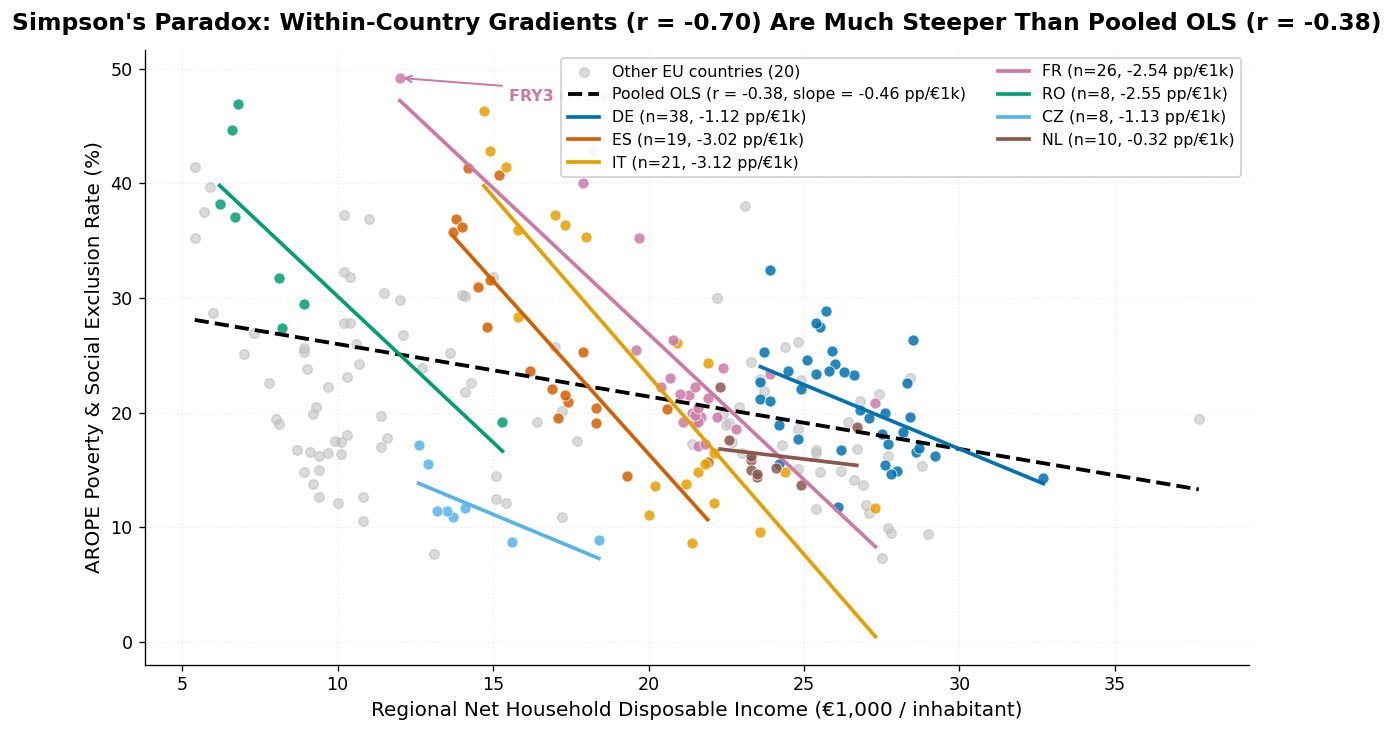

In [3]:
# Figure 01: Simpson's Paradox — Pooled vs. Within-Country Income-Poverty Gradients
highlight_countries = ["DE", "ES", "IT", "FR", "RO", "CZ", "NL"]
highlight_colors = {
    "DE": PALETTE["blue"],
    "ES": PALETTE["vermilion"],
    "IT": PALETTE["orange"],
    "FR": PALETTE["reddish_purple"],
    "RO": PALETTE["bluish_green"],
    "CZ": PALETTE["sky_blue"],
    "NL": "#8C564B",
}

fig, ax = plt.subplots(figsize=(10, 6.2))

# Background points for all other countries
other_mask = ~df["country"].isin(highlight_countries)
ax.scatter(
    df.loc[other_mask, "disposable_income"] / 1000.0,
    df.loc[other_mask, "arope_rate"],
    color=PALETTE["light_gray"],
    alpha=0.55,
    s=32,
    label="Other EU countries (20)",
    zorder=2,
)

# Pooled OLS line
x_all = df["disposable_income"].values / 1000.0
y_all = df["arope_rate"].values
b1_pool, b0_pool = np.polyfit(x_all, y_all, 1)
x_grid = np.linspace(x_all.min(), x_all.max(), 200)
ax.plot(
    x_grid,
    b0_pool + b1_pool * x_grid,
    color="black",
    linestyle="--",
    linewidth=2.3,
    label=f"Pooled OLS (r = {pooled_r:.2f}, slope = {b1_pool:.2f} pp/€1k)",
    zorder=4,
)

# Highlighted country points and OLS fits
for c in highlight_countries:
    sub = df[df["country"] == c]
    xc = sub["disposable_income"].values / 1000.0
    yc = sub["arope_rate"].values
    col = highlight_colors[c]
    ax.scatter(xc, yc, color=col, alpha=0.85, s=44, edgecolor="white", linewidth=0.5, zorder=3)
    b1_c, b0_c = np.polyfit(xc, yc, 1)
    xg = np.linspace(xc.min(), xc.max(), 50)
    ax.plot(xg, b0_c + b1_c * xg, color=col, linewidth=2.2, label=f"{c} (n={len(sub)}, {b1_c:.2f} pp/€1k)", zorder=5)

# Annotate upper-tail outlier FRY3 (French Guiana)
fry3 = df[df["geo"] == "FRY3"].iloc[0]
ax.annotate(
    f"FRY3 (French Guiana, {fry3['arope_rate']:.1f}%)",
    xy=(fry3["disposable_income"] / 1000.0, fry3["arope_rate"]),
    xytext=(fry3["disposable_income"] / 1000.0 + 3.5, fry3["arope_rate"] - 2.0),
    fontsize=9.5,
    fontweight="bold",
    color=PALETTE["reddish_purple"],
    arrowprops=dict(arrowstyle="->", color=PALETTE["reddish_purple"], lw=1.2),
)

ax.set_xlabel("Regional Net Household Disposable Income (€1,000 / inhabitant)")
ax.set_ylabel("AROPE Poverty & Social Exclusion Rate (%)")
ax.set_title(
    f"Simpson's Paradox: Within-Country Gradients (r = {within_r:.2f}) Are Much Steeper Than Pooled OLS (r = {pooled_r:.2f})",
    pad=12,
)
ax.legend(loc="upper right", frameon=True, framealpha=0.92, ncol=2, fontsize=9.5)
plt.tight_layout()
save_fig(fig, "01_eda_simpsons_paradox.png")
plt.show()

Saved: figures/02_eda_distributions_and_groups.png


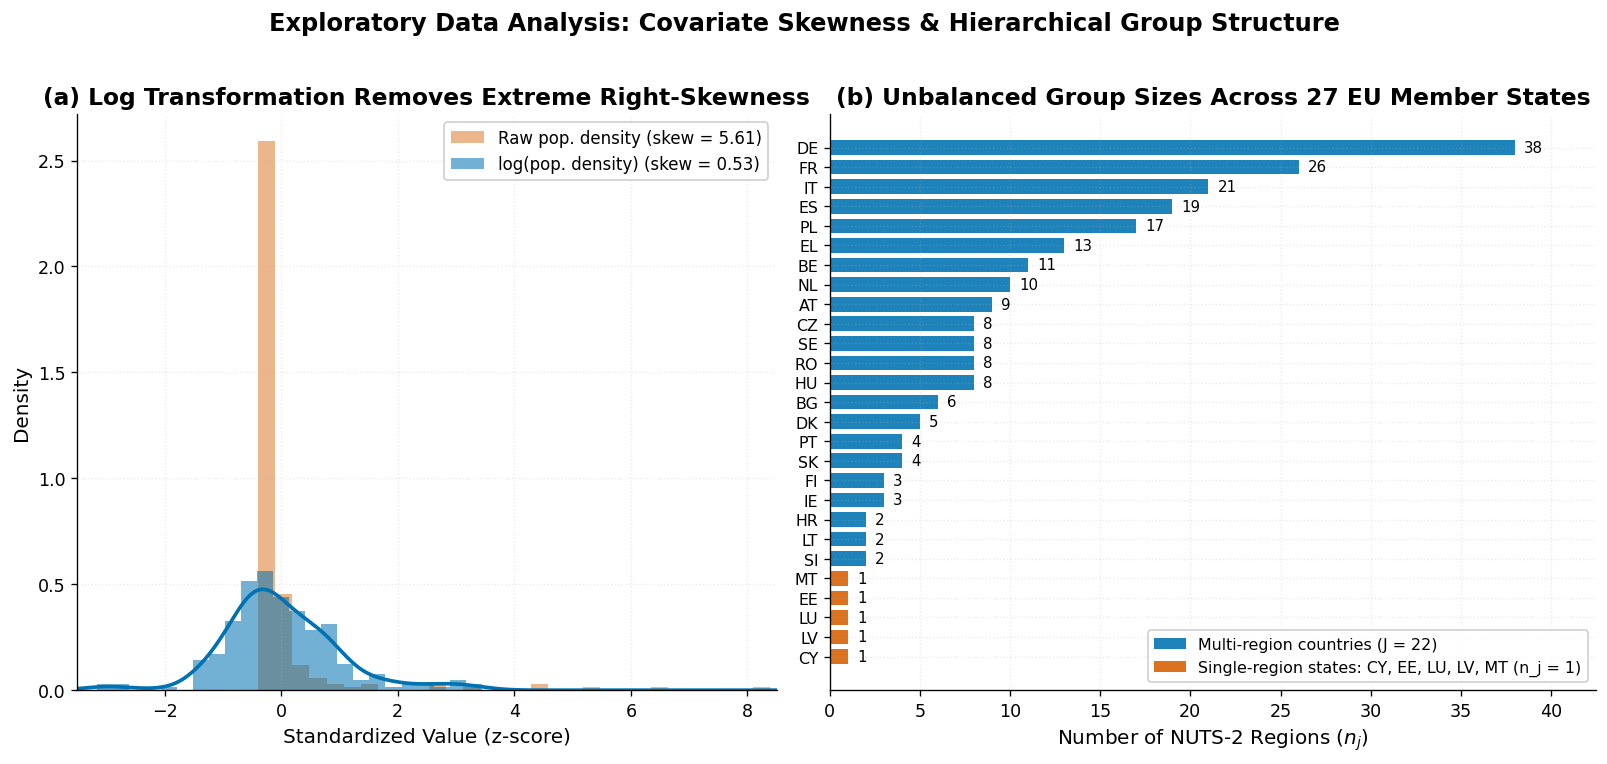

In [4]:
# Figure 02: Population Density Skewness Reduction & Unbalanced NUTS-2 Group Sizes
fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.2), gridspec_kw={"width_ratios": [1.05, 1.15]})

# Panel (a): Raw vs. Log population density (z-standardized overlay for direct shape comparison)
ax = axes[0]
raw_z = (df["pop_density"] - df["pop_density"].mean()) / df["pop_density"].std()
log_z = df["log_pop_density_scaled"]
ax.hist(raw_z, bins=30, density=True, alpha=0.45, color=PALETTE["vermilion"],
        label=f"Raw pop. density (skew = {raw_skew:.2f})")
ax.hist(log_z, bins=24, density=True, alpha=0.55, color=PALETTE["blue"],
        label=f"log(pop. density) (skew = {log_skew:.2f})")
x_kde = np.linspace(-3.5, 8.5, 300)
ax.plot(x_kde, stats.gaussian_kde(log_z)(x_kde), color=PALETTE["blue"], lw=2.2)
ax.set_xlim(-3.5, 8.5)
ax.set_xlabel("Standardized Value (z-score)")
ax.set_ylabel("Density")
ax.set_title("(a) Log Transformation Removes Extreme Right-Skewness")
ax.legend(loc="upper right", frameon=True, framealpha=0.92)

# Panel (b): Horizontal bar chart of NUTS-2 region counts per country
ax = axes[1]
counts_sorted = df["country"].value_counts().sort_values(ascending=True)
bar_colors = [
    PALETTE["vermilion"] if n == 1 else PALETTE["blue"]
    for n in counts_sorted.values
]
y_pos = np.arange(len(counts_sorted))
ax.barh(y_pos, counts_sorted.values, color=bar_colors, alpha=0.88, height=0.75)
ax.set_yticks(y_pos)
ax.set_yticklabels(counts_sorted.index, fontsize=9.5)
for idx, val in enumerate(counts_sorted.values):
    ax.text(val + 0.5, idx, str(val), va="center", ha="left", fontsize=9)
ax.set_xlim(0, counts_sorted.max() + 4.5)
ax.set_xlabel("Number of NUTS-2 Regions ($n_j$)")
ax.set_title("(b) Unbalanced Group Sizes Across 27 EU Member States")

# Custom legend for single-region highlight
from matplotlib.patches import Patch
ax.legend(
    handles=[
        Patch(facecolor=PALETTE["blue"], alpha=0.88, label="Multi-region countries (J = 22)"),
        Patch(facecolor=PALETTE["vermilion"], alpha=0.88, label="Single-region states: CY, EE, LU, LV, MT (n_j = 1)"),
    ],
    loc="lower right",
    frameon=True,
    framealpha=0.92,
    fontsize=9.5,
)

fig.suptitle("Exploratory Data Analysis: Covariate Skewness & Hierarchical Group Structure",
             fontsize=14.5, fontweight="bold", y=1.02)
plt.tight_layout()
save_fig(fig, "02_eda_distributions_and_groups.png")
plt.show()

## Section 2: Model Definitions & Prior Predictive Checks

Both models specify a continuous Gaussian likelihood on globally $z$-standardized AROPE ($y_i$):
$$y_i \sim \mathcal{N}(\mu_i, \sigma)$$

### Model 1 — Pooled Baseline (Complete Pooling)
$$\mu_i = \alpha + \beta_{\text{inc}} x_{\text{inc}, i} + \beta_{\text{dens}} x_{\text{dens}, i}$$
- $\alpha \sim \mathcal{N}(0, 1.5)$, $\beta_{\text{inc}} \sim \mathcal{N}(0, 1.5)$, $\beta_{\text{dens}} \sim \mathcal{N}(0, 1.0)$, $\sigma \sim \text{Exponential}(1.0)$.
- *Calibration rationale:* Setting $\beta_{\text{inc}} \sim \mathcal{N}(0, 1.5)$ (wider than $0.5$) accommodates steep within-country standardized slopes ($-2.5$ to $-3.4$) revealed by Simpson's paradox without imposing improper flat priors.

### Model 2 — Hierarchical Varying Intercepts & Varying Slopes (Partial Pooling)
$$\mu_i = (\mu_\alpha + u_{0, j[i]}) + (\mu_\beta + u_{1, j[i]}) x_{\text{inc}, i} + \beta_{\text{dens}} x_{\text{dens}, i}$$
- Population-level priors: $\mu_\alpha \sim \mathcal{N}(0, 1.5)$, $\mu_\beta \sim \mathcal{N}(0, 1.5)$, $\beta_{\text{dens}} \sim \mathcal{N}(0, 1.0)$, $\sigma \sim \text{Exponential}(1.0)$.
- Group-level hyperpriors: $u_{0j} \sim \mathcal{N}(0, \tau_\alpha)$, $u_{1j} \sim \mathcal{N}(0, \tau_\beta)$ with $\tau_\alpha, \tau_\beta \sim \text{HalfNormal}(1.0)$ using Bambi's non-centered offset parameterization.
- **Explicit Bambi Default Verification:** As confirmed by `print(model_2)` below, Bambi treats `(1 + disposable_income_scaled | country)` as **independent** normal group-level effects (no separate LKJ correlation matrix parameter between $u_{0j}$ and $u_{1j}$). Every parameter in both models has an explicit, proper prior—zero improper flat priors are used.

In [ ]:
FORMULA_M1 = "arope_scaled ~ disposable_income_scaled + log_pop_density_scaled"
FORMULA_M2 = (
    "arope_scaled ~ disposable_income_scaled + log_pop_density_scaled "
    "+ (1 + disposable_income_scaled | country)"
)

BASE_PRIORS_M1 = {
    "Intercept": bmb.Prior("Normal", mu=0, sigma=1.5),
    "disposable_income_scaled": bmb.Prior("Normal", mu=0, sigma=1.5),
    "log_pop_density_scaled": bmb.Prior("Normal", mu=0, sigma=1.0),
    "sigma": bmb.Prior("Exponential", lam=1.0),
}

BASE_PRIORS_M2 = {
    "Intercept": bmb.Prior("Normal", mu=0, sigma=1.5),
    "disposable_income_scaled": bmb.Prior("Normal", mu=0, sigma=1.5),
    "log_pop_density_scaled": bmb.Prior("Normal", mu=0, sigma=1.0),
    "1|country": bmb.Prior("Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=1.0)),
    "disposable_income_scaled|country": bmb.Prior(
        "Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=1.0)
    ),
    "sigma": bmb.Prior("Exponential", lam=1.0),
}

model_1 = bmb.Model(FORMULA_M1, data=df, family="gaussian", priors=BASE_PRIORS_M1)
model_2 = bmb.Model(FORMULA_M2, data=df, family="gaussian", priors=BASE_PRIORS_M2)

print("=== Model 1 Full Specification (All Explicit & Default Priors) ===")
print(model_1)
print("\n=== Model 2 Full Specification (All Explicit & Default Priors) ===")
print(model_2)

=== Model 1 Full Specification (All Explicit & Default Priors) ===
       Formula: arope_scaled ~ disposable_income_scaled + log_pop_density_scaled
        Family: gaussian
          Link: mu = identity
  Observations: 232
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 0.0, sigma: 1.5)
            disposable_income_scaled ~ Normal(mu: 0.0, sigma: 1.5)
            log_pop_density_scaled ~ Normal(mu: 0.0, sigma: 1.0)
        
        Auxiliary parameters
            sigma ~ Exponential(lam: 1.0)

=== Model 2 Full Specification (All Explicit & Default Priors) ===
       Formula: arope_scaled ~ disposable_income_scaled + log_pop_density_scaled + (1 + disposable_income_scaled | country)
        Family: gaussian
          Link: mu = identity
  Observations: 232
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 0.0, sigma: 1.5)
            disposable_income_scaled ~ Normal(mu: 0.0, sigma: 1.5)
   

Sampling: [Intercept, arope_scaled, arope_scaled_sigma, disposable_income_scaled, log_pop_density_scaled]


Sampling: [1|country_offset, 1|country_sigma, Intercept, arope_scaled, arope_scaled_sigma, disposable_income_scaled, disposable_income_scaled|country_offset, disposable_income_scaled|country_sigma, log_pop_density_scaled]


Model 1 (Pooled)       prior predictive AROPE (%) | 95% interval: [-23.0, 68.7] | median: 22.2
Model 2 (Hierarchical) prior predictive AROPE (%) | 95% interval: [-28.3, 72.6] | median: 21.2


Saved: figures/03_prior_predictive_check.png


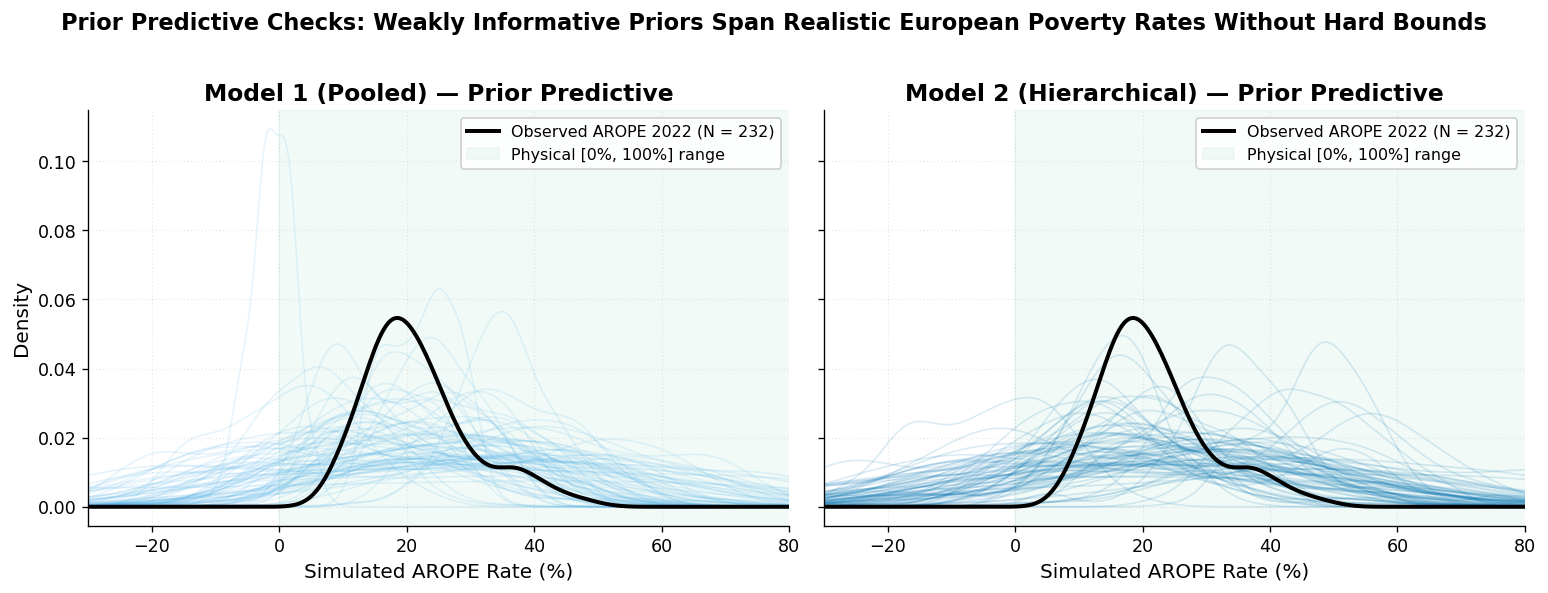

In [6]:
# Prior Predictive Checks (Before Fitting to Data)
model_1.build()
model_2.build()

prior_1 = model_1.prior_predictive(draws=500, random_seed=RANDOM_SEED)
prior_2 = model_2.prior_predictive(draws=500, random_seed=RANDOM_SEED)

# Back-transform prior predictive draws to original AROPE (%) scale
pp1_pct = prior_1.prior_predictive["arope_scaled"].values.reshape(-1, len(df)) * AROPE_SD + AROPE_MEAN
pp2_pct = prior_2.prior_predictive["arope_scaled"].values.reshape(-1, len(df)) * AROPE_SD + AROPE_MEAN

# Print concise prior predictive coverage quantiles
for name, arr in [("Model 1 (Pooled)", pp1_pct), ("Model 2 (Hierarchical)", pp2_pct)]:
    q = np.quantile(arr, [0.025, 0.25, 0.50, 0.75, 0.975])
    print(f"{name:22s} prior predictive AROPE (%) | 95% interval: [{q[0]:.1f}, {q[4]:.1f}] | median: {q[2]:.1f}")

# Figure 03: Prior Predictive Check
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
x_grid = np.linspace(-30, 80, 300)
obs_kde = stats.gaussian_kde(df["arope_rate"].values)(x_grid)

for ax, arr, title, col in [
    (axes[0], pp1_pct, "Model 1 (Pooled) — Prior Predictive", PALETTE["sky_blue"]),
    (axes[1], pp2_pct, "Model 2 (Hierarchical) — Prior Predictive", PALETTE["blue"]),
]:
    for draw_idx in range(80):
        sample_vals = arr[draw_idx]
        ax.plot(x_grid, stats.gaussian_kde(sample_vals)(x_grid), color=col, alpha=0.14, lw=1.0)
    ax.plot(x_grid, obs_kde, color="black", lw=2.4, label="Observed AROPE 2022 (N = 232)")
    ax.axvspan(0, 100, color=PALETTE["bluish_green"], alpha=0.05, label="Physical [0%, 100%] range")
    ax.set_xlim(-30, 80)
    ax.set_xlabel("Simulated AROPE Rate (%)")
    ax.set_title(title)
    ax.legend(loc="upper right", frameon=True, framealpha=0.92, fontsize=9.5)

axes[0].set_ylabel("Density")
fig.suptitle(
    "Prior Predictive Checks: Weakly Informative Priors Span Realistic European Poverty Rates Without Hard Bounds",
    fontsize=13.5, fontweight="bold", y=1.02,
)
plt.tight_layout()
save_fig(fig, "03_prior_predictive_check.png")
plt.show()

## Section 3: MCMC Inference Details

Both models are fitted via PyMC's No-U-Turn Sampler (NUTS) with identical, reproducible settings:
- **`chains = 4`, `tune = 1000`, `draws = 2000`** ($8{,}000$ post-warmup draws total): 4 independent chains enable reliable split-$\hat{R}$ diagnostics and high Bulk/Tail ESS ($> 400$ target).
- **`target_accept = 0.95`**: Elevated step-size adaptation target suppresses funnel-geometry divergences common in hierarchical variance components ($\tau_\alpha, \tau_\beta$) with unbalanced and single-region groups.
- **`omit_offsets = False`**: Preserves Bambi's non-centered offset draws in `idata.posterior` so `pm.sample_posterior_predictive` conditions faithfully on the fitted group-level posterior rather than re-sampling offsets from the prior.
- **`idata_kwargs = {"log_likelihood": True}`**: Stores pointwise log-likelihoods for PSIS-LOO-CV.
- **`random_seed = 42`**: Ensures full reproducibility.

In [7]:
MCMC_KWARGS = dict(
    draws=2000,
    tune=1000,
    chains=4,
    target_accept=0.95,
    random_seed=RANDOM_SEED,
    omit_offsets=False,
    idata_kwargs={"log_likelihood": True},
    progressbar=False,
)


def fit_and_sample_ppc(model: bmb.Model, label: str, **kwargs):
    print(f"Sampling {label} (4 chains x {kwargs['draws']} draws, tune={kwargs['tune']}, target_accept={kwargs['target_accept']})...")
    idata = model.fit(**kwargs)
    pm.sample_posterior_predictive(
        idata,
        model=model.backend.model,
        var_names=["arope_scaled"],
        extend_inferencedata=True,
        random_seed=RANDOM_SEED,
        progressbar=False,
    )
    return idata


idata_1 = fit_and_sample_ppc(model_1, "Model 1 (Pooled)", **MCMC_KWARGS)
idata_2 = fit_and_sample_ppc(model_2, "Model 2 (Hierarchical)", **MCMC_KWARGS)

# Version-agnostic residual SD variable name (Bambi 0.13 uses 'arope_scaled_sigma'; >=0.14 uses 'sigma')
SIGMA_VAR = "sigma" if "sigma" in idata_2.posterior else "arope_scaled_sigma"
POP_VARS_M1 = ["Intercept", "disposable_income_scaled", "log_pop_density_scaled", SIGMA_VAR]
POP_VARS_M2 = [
    "Intercept",
    "disposable_income_scaled",
    "log_pop_density_scaled",
    "1|country_sigma",
    "disposable_income_scaled|country_sigma",
    SIGMA_VAR,
]
print(f"Sampling complete. Residual SD variable name in posterior: '{SIGMA_VAR}'")

Sampling Model 1 (Pooled) (4 chains x 2000 draws, tune=1000, target_accept=0.95)...


Auto-assigning NUTS sampler...


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [arope_scaled_sigma, Intercept, disposable_income_scaled, log_pop_density_scaled]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 1 seconds.


... (5 outputs left out)

NUTS: [arope_scaled_sigma, Intercept, disposable_income_scaled, log_pop_density_scaled, 1|country_sigma, 1|country_offset, disposable_income_scaled|country_sigma, disposable_income_scaled|country_offset]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 17 seconds.


Sampling: [arope_scaled]


Sampling complete. Residual SD variable name in posterior: 'arope_scaled_sigma'


## Section 4: Convergence Diagnostics (All Models)

Following Vehtari et al. (2021), we assess MCMC convergence across **all** sampled parameters in both models using:
- Worst-case (maximum) split-$\hat{R} \le 1.01$
- Minimum Bulk-ESS and Tail-ESS $> 400$
- Zero divergent transitions (`diverging == 0`)
- Energy Bayesian Fraction of Missing Information ($\text{E-BFMI} \ge 0.30$ across all chains)
- Visual **rank histograms** (`az.plot_rank`) for key population parameters and variance components across both models.

In [8]:
def convergence_row(idata, model_name: str) -> dict:
    # Summarize all posterior parameters (excluding deterministic offset duplicates if identical, or full posterior)
    summary = az.summary(idata, round_to=4)
    bfmi_vals = az.bfmi(idata)
    return {
        "Model": model_name,
        "Params": len(summary),
        "Max R-hat": round(float(summary["r_hat"].max()), 3),
        "Min Bulk-ESS": int(round(float(summary["ess_bulk"].min()))),
        "Min Tail-ESS": int(round(float(summary["ess_tail"].min()))),
        "Divergences": int(idata.sample_stats["diverging"].sum().item()),
        "Min E-BFMI": round(float(np.min(bfmi_vals)), 2),
        "Status": (
            "PASS"
            if (
                summary["r_hat"].max() <= 1.01
                and summary["ess_bulk"].min() > 400
                and summary["ess_tail"].min() > 400
                and int(idata.sample_stats["diverging"].sum().item()) == 0
                and np.min(bfmi_vals) >= 0.30
            )
            else "CHECK"
        ),
    }


conv_df = pd.DataFrame([
    convergence_row(idata_1, "Model 1 (Pooled)"),
    convergence_row(idata_2, "Model 2 (Hierarchical)"),
]).set_index("Model")
display(conv_df)

assert (conv_df["Status"] == "PASS").all(), "Convergence check failed for a primary model!"

,Params,Max R-hat,Min Bulk-ESS,Min Tail-ESS,Divergences,Min E-BFMI,Status
Model,,,,,,,
Model 1 (Pooled),4,1.001,8406,5484,0,1.00,PASS
Model 2 (Hierarchical),114,1.002,2030,3026,0,0.64,PASS


Saved: figures/04_convergence_diagnostics.png


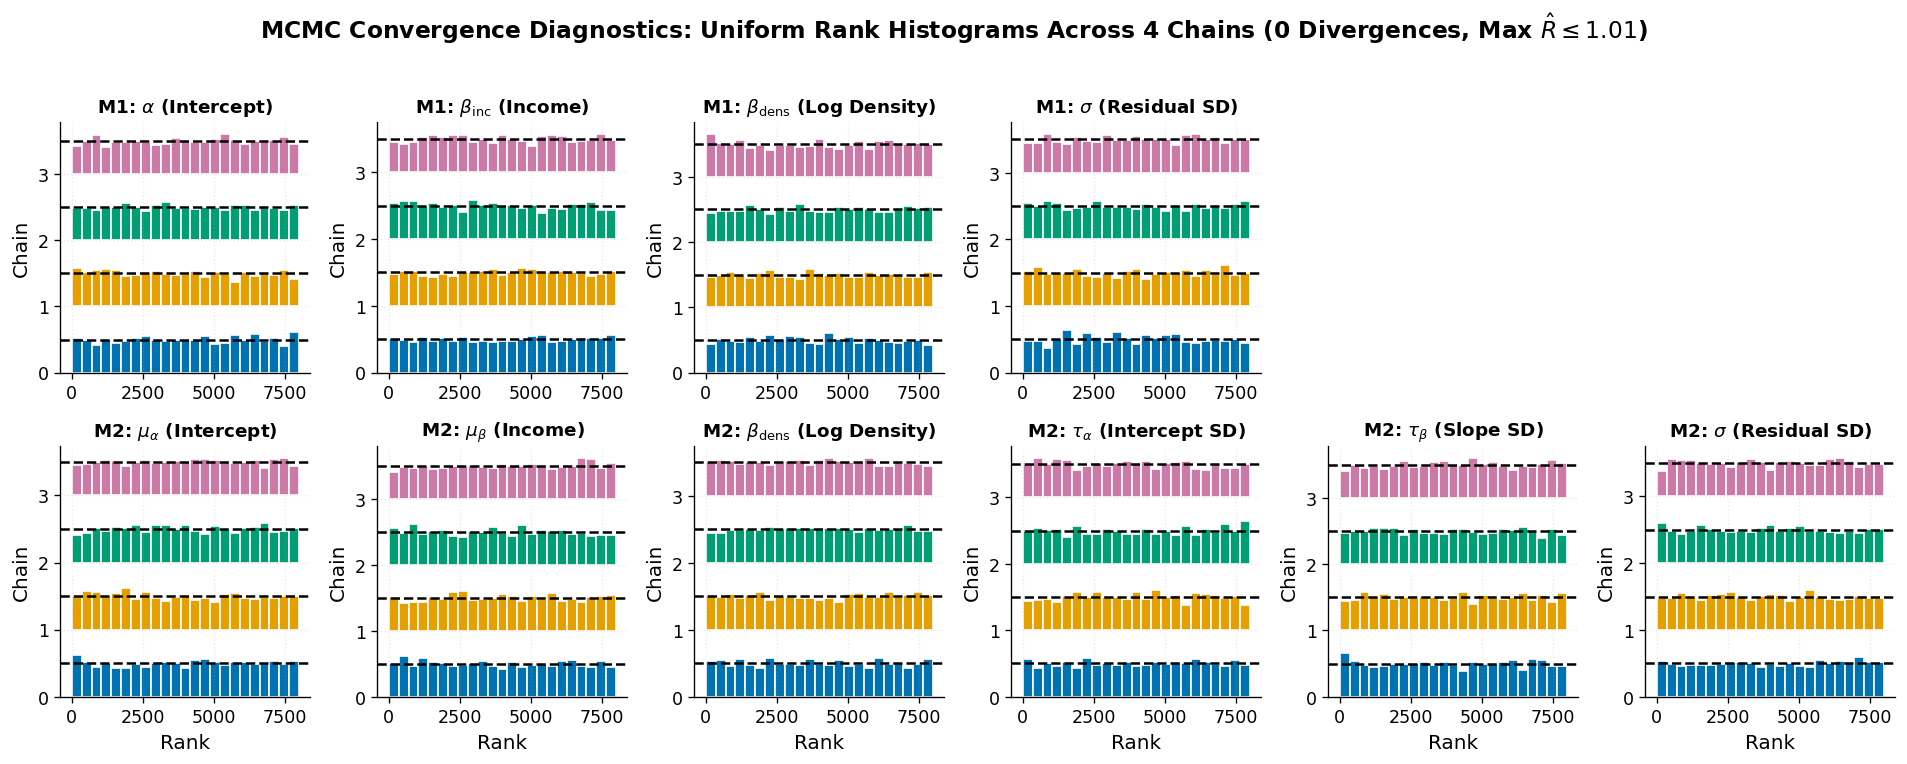

In [9]:
# Figure 04: Vehtari-Style Rank Histograms Across Both Models
PARAM_LABELS = {
    "Intercept": r"$\alpha$ (Intercept)",
    "disposable_income_scaled": r"$\beta_{\mathrm{inc}}$ (Income)",
    "log_pop_density_scaled": r"$\beta_{\mathrm{dens}}$ (Log Density)",
    SIGMA_VAR: r"$\sigma$ (Residual SD)",
    "1|country_sigma": r"$\tau_\alpha$ (Intercept SD)",
    "disposable_income_scaled|country_sigma": r"$\tau_\beta$ (Slope SD)",
}

fig, axes = plt.subplots(2, 6, figsize=(16, 6.2))
chain_colors = [PALETTE["blue"], PALETTE["orange"], PALETTE["bluish_green"], PALETTE["reddish_purple"]]

# Top row: Model 1 (4 parameters; hide last 2 panels cleanly)
for idx, var in enumerate(POP_VARS_M1):
    az.plot_rank(
        idata_1,
        var_names=[var],
        kind="bars",
        colors=chain_colors,
        ax=axes[0, idx],
    )
    axes[0, idx].set_title(f"M1: {PARAM_LABELS[var]}", fontsize=11, fontweight="bold")
    axes[0, idx].set_xlabel("")
for idx in [4, 5]:
    axes[0, idx].axis("off")

# Bottom row: Model 2 (6 population & variance parameters)
for idx, var in enumerate(POP_VARS_M2):
    az.plot_rank(
        idata_2,
        var_names=[var],
        kind="bars",
        colors=chain_colors,
        ax=axes[1, idx],
    )
    lbl = PARAM_LABELS[var].replace(r"$\alpha$", r"$\mu_\alpha$").replace(r"$\beta_{\mathrm{inc}}$", r"$\mu_\beta$")
    axes[1, idx].set_title(f"M2: {lbl}", fontsize=11, fontweight="bold")
    axes[1, idx].set_xlabel("Rank")

fig.suptitle(
    "MCMC Convergence Diagnostics: Uniform Rank Histograms Across 4 Chains (0 Divergences, Max $\hat{R} \leq 1.01$)",
    fontsize=14, fontweight="bold", y=1.02,
)
plt.tight_layout()
save_fig(fig, "04_convergence_diagnostics.png")
plt.show()

## Section 5: Posterior Predictive Checks — PPCs (All Models)

Following Gabry et al. (2019), we evaluate whether posterior predictive replications ($y^{\text{rep}}$) reproduce the empirical distribution, tail behavior, calibration, and country-level structure of the 2022 Eurostat AROPE data:
1. **KDE Overlay & LOO-PIT ECDF Calibration (`05_ppc_kde_and_loopit.png`):** Checks overall marginal density (on the original AROPE % scale) and leave-one-out probability integral transform (LOO-PIT) calibration.
2. **Tail & Shape Test Statistics (`06_ppc_test_statistics.png`):** Checks whether each model reproduces the empirical maximum (`FRY3` = 49.2%) and distribution skewness.
3. **Grouped Country-Level PPC (`07_ppc_grouped_by_country.png`):** Compares observed country means against 50% and 95% posterior predictive intervals across all 27 EU countries.

Saved: figures/05_ppc_kde_and_loopit.png


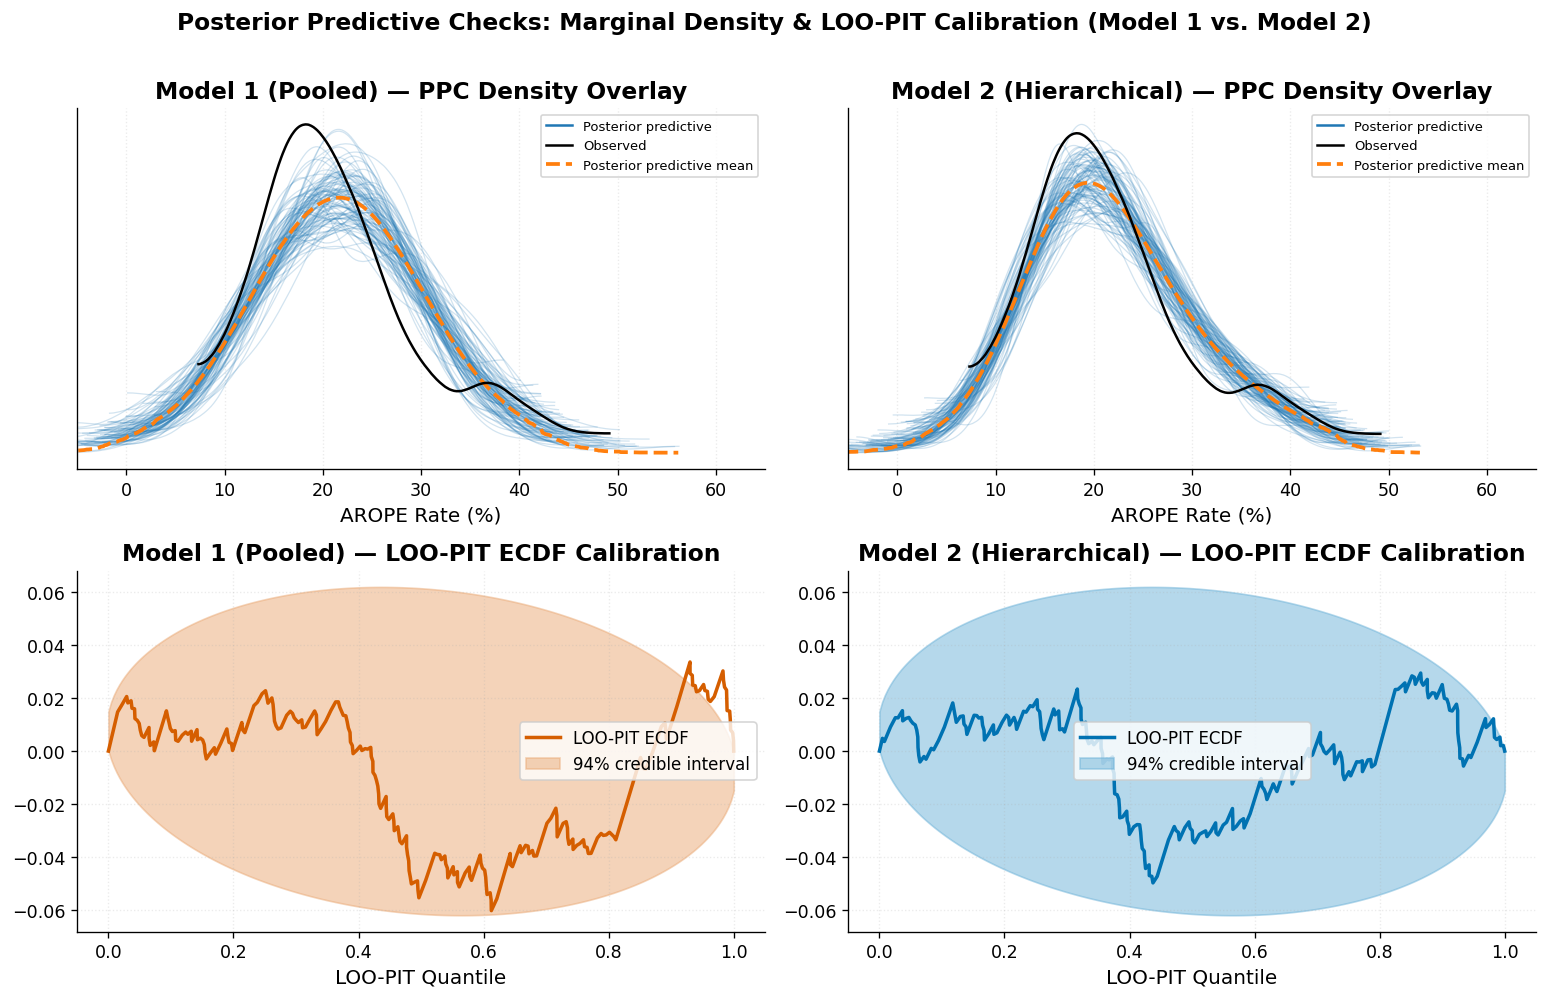

In [10]:
# Back-transform posterior predictive draws to original AROPE (%) scale
y_obs_pct = df["arope_rate"].values
yrep_1_pct = idata_1.posterior_predictive["arope_scaled"].values * AROPE_SD + AROPE_MEAN  # (chains, draws, N)
yrep_2_pct = idata_2.posterior_predictive["arope_scaled"].values * AROPE_SD + AROPE_MEAN

# Build lightweight ArviZ InferenceData objects on the original % scale for clean KDE PPC plots
ppc_id1_pct = az.from_dict(
    observed_data={"AROPE (%)": y_obs_pct},
    posterior_predictive={"AROPE (%)": yrep_1_pct},
)
ppc_id2_pct = az.from_dict(
    observed_data={"AROPE (%)": y_obs_pct},
    posterior_predictive={"AROPE (%)": yrep_2_pct},
)

# Figure 05: KDE Overlay (Top) & LOO-PIT ECDF Calibration (Bottom)
fig, axes = plt.subplots(2, 2, figsize=(13, 8.2))

az.plot_ppc(ppc_id1_pct, kind="kde", num_pp_samples=100, random_seed=RANDOM_SEED, ax=axes[0, 0])
axes[0, 0].set_title("Model 1 (Pooled) — PPC Density Overlay")
axes[0, 0].set_xlabel("AROPE Rate (%)")
axes[0, 0].set_xlim(-5, 65)

az.plot_ppc(ppc_id2_pct, kind="kde", num_pp_samples=100, random_seed=RANDOM_SEED, ax=axes[0, 1])
axes[0, 1].set_title("Model 2 (Hierarchical) — PPC Density Overlay")
axes[0, 1].set_xlabel("AROPE Rate (%)")
axes[0, 1].set_xlim(-5, 65)

az.plot_loo_pit(idata=idata_1, y="arope_scaled", ecdf=True, color=PALETTE["vermilion"], ax=axes[1, 0])
axes[1, 0].set_title("Model 1 (Pooled) — LOO-PIT ECDF Calibration")
axes[1, 0].set_xlabel("LOO-PIT Quantile")

az.plot_loo_pit(idata=idata_2, y="arope_scaled", ecdf=True, color=PALETTE["blue"], ax=axes[1, 1])
axes[1, 1].set_title("Model 2 (Hierarchical) — LOO-PIT ECDF Calibration")
axes[1, 1].set_xlabel("LOO-PIT Quantile")

fig.suptitle(
    "Posterior Predictive Checks: Marginal Density & LOO-PIT Calibration (Model 1 vs. Model 2)",
    fontsize=14, fontweight="bold", y=1.01,
)
plt.tight_layout()
save_fig(fig, "05_ppc_kde_and_loopit.png")
plt.show()

PPC Max  (obs FRY3 = 49.2%) | M1 median = 45.3% (p=0.15) | M2 median = 46.9% (p=0.24)
PPC Skew (obs = 0.93)       | M1 median = 0.01 (p=0.00) | M2 median = 0.37 (p=0.00)


Saved: figures/06_ppc_test_statistics.png


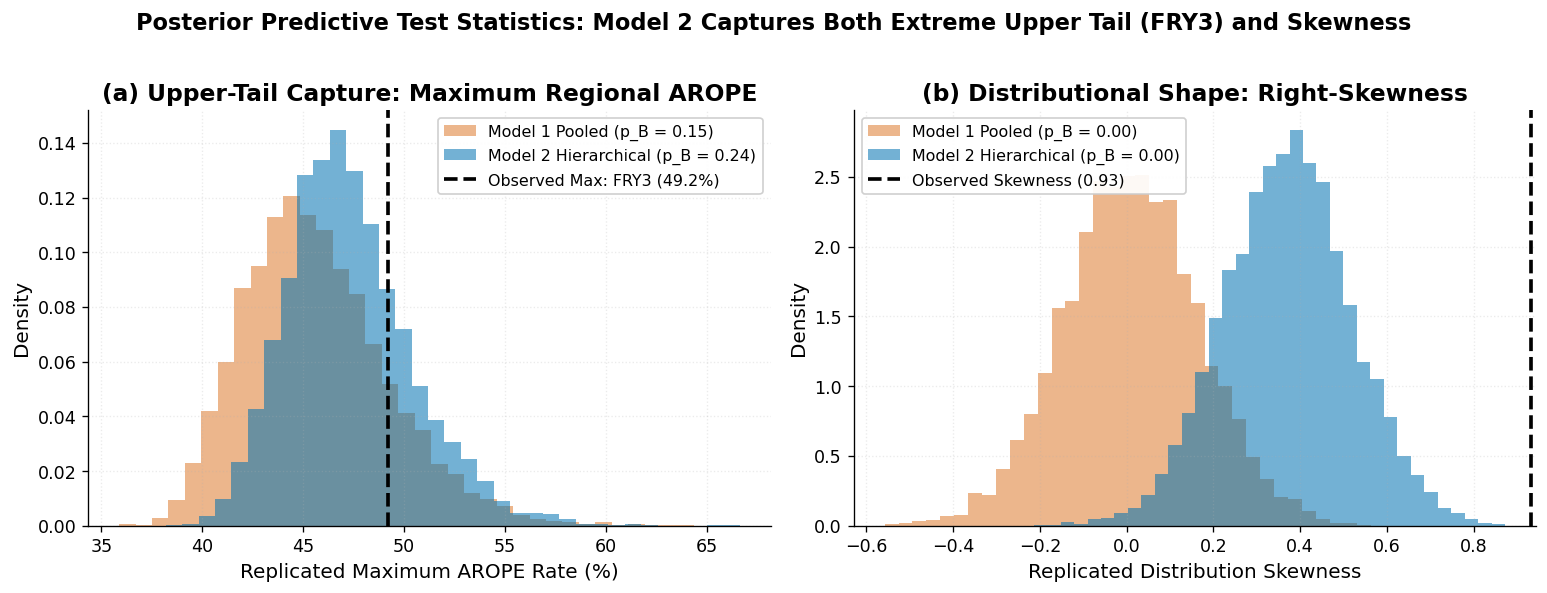

In [11]:
# Figure 06: Posterior Predictive Test Statistics (Maximum & Skewness)
yrep_1_flat = yrep_1_pct.reshape(-1, len(df))
yrep_2_flat = yrep_2_pct.reshape(-1, len(df))

obs_max = float(np.max(y_obs_pct))
obs_skew = float(stats.skew(y_obs_pct))

max_1 = yrep_1_flat.max(axis=1)
max_2 = yrep_2_flat.max(axis=1)
skew_1 = stats.skew(yrep_1_flat, axis=1)
skew_2 = stats.skew(yrep_2_flat, axis=1)

p_max_1 = float(np.mean(max_1 >= obs_max))
p_max_2 = float(np.mean(max_2 >= obs_max))
p_skew_1 = float(np.mean(skew_1 >= obs_skew))
p_skew_2 = float(np.mean(skew_2 >= obs_skew))

print(f"PPC Max  (obs FRY3 = {obs_max:.1f}%) | M1 median = {np.median(max_1):.1f}% (p={p_max_1:.2f}) | M2 median = {np.median(max_2):.1f}% (p={p_max_2:.2f})")
print(f"PPC Skew (obs = {obs_skew:.2f})       | M1 median = {np.median(skew_1):.2f} (p={p_skew_1:.2f}) | M2 median = {np.median(skew_2):.2f} (p={p_skew_2:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Panel (a): Maximum AROPE (%)
ax = axes[0]
ax.hist(max_1, bins=35, density=True, alpha=0.45, color=PALETTE["vermilion"],
        label=f"Model 1 Pooled (p_B = {p_max_1:.2f})")
ax.hist(max_2, bins=35, density=True, alpha=0.55, color=PALETTE["blue"],
        label=f"Model 2 Hierarchical (p_B = {p_max_2:.2f})")
ax.axvline(obs_max, color="black", linestyle="--", lw=2.2, label=f"Observed Max: FRY3 ({obs_max:.1f}%)")
ax.set_xlabel("Replicated Maximum AROPE Rate (%)")
ax.set_ylabel("Density")
ax.set_title("(a) Upper-Tail Capture: Maximum Regional AROPE")
ax.legend(loc="upper right", frameon=True, framealpha=0.92, fontsize=9.5)

# Panel (b): Skewness
ax = axes[1]
ax.hist(skew_1, bins=35, density=True, alpha=0.45, color=PALETTE["vermilion"],
        label=f"Model 1 Pooled (p_B = {p_skew_1:.2f})")
ax.hist(skew_2, bins=35, density=True, alpha=0.55, color=PALETTE["blue"],
        label=f"Model 2 Hierarchical (p_B = {p_skew_2:.2f})")
ax.axvline(obs_skew, color="black", linestyle="--", lw=2.2, label=f"Observed Skewness ({obs_skew:.2f})")
ax.set_xlabel("Replicated Distribution Skewness")
ax.set_ylabel("Density")
ax.set_title("(b) Distributional Shape: Right-Skewness")
ax.legend(loc="upper left", frameon=True, framealpha=0.92, fontsize=9.5)

fig.suptitle(
    "Posterior Predictive Test Statistics: Model 2 Captures Both Extreme Upper Tail (FRY3) and Skewness",
    fontsize=13.5, fontweight="bold", y=1.02,
)
plt.tight_layout()
save_fig(fig, "06_ppc_test_statistics.png")
plt.show()

95% Country-Mean PPC Coverage | Model 1: 21/27 (77.8%) | Model 2: 27/27 (100.0%)


Saved: figures/07_ppc_grouped_by_country.png


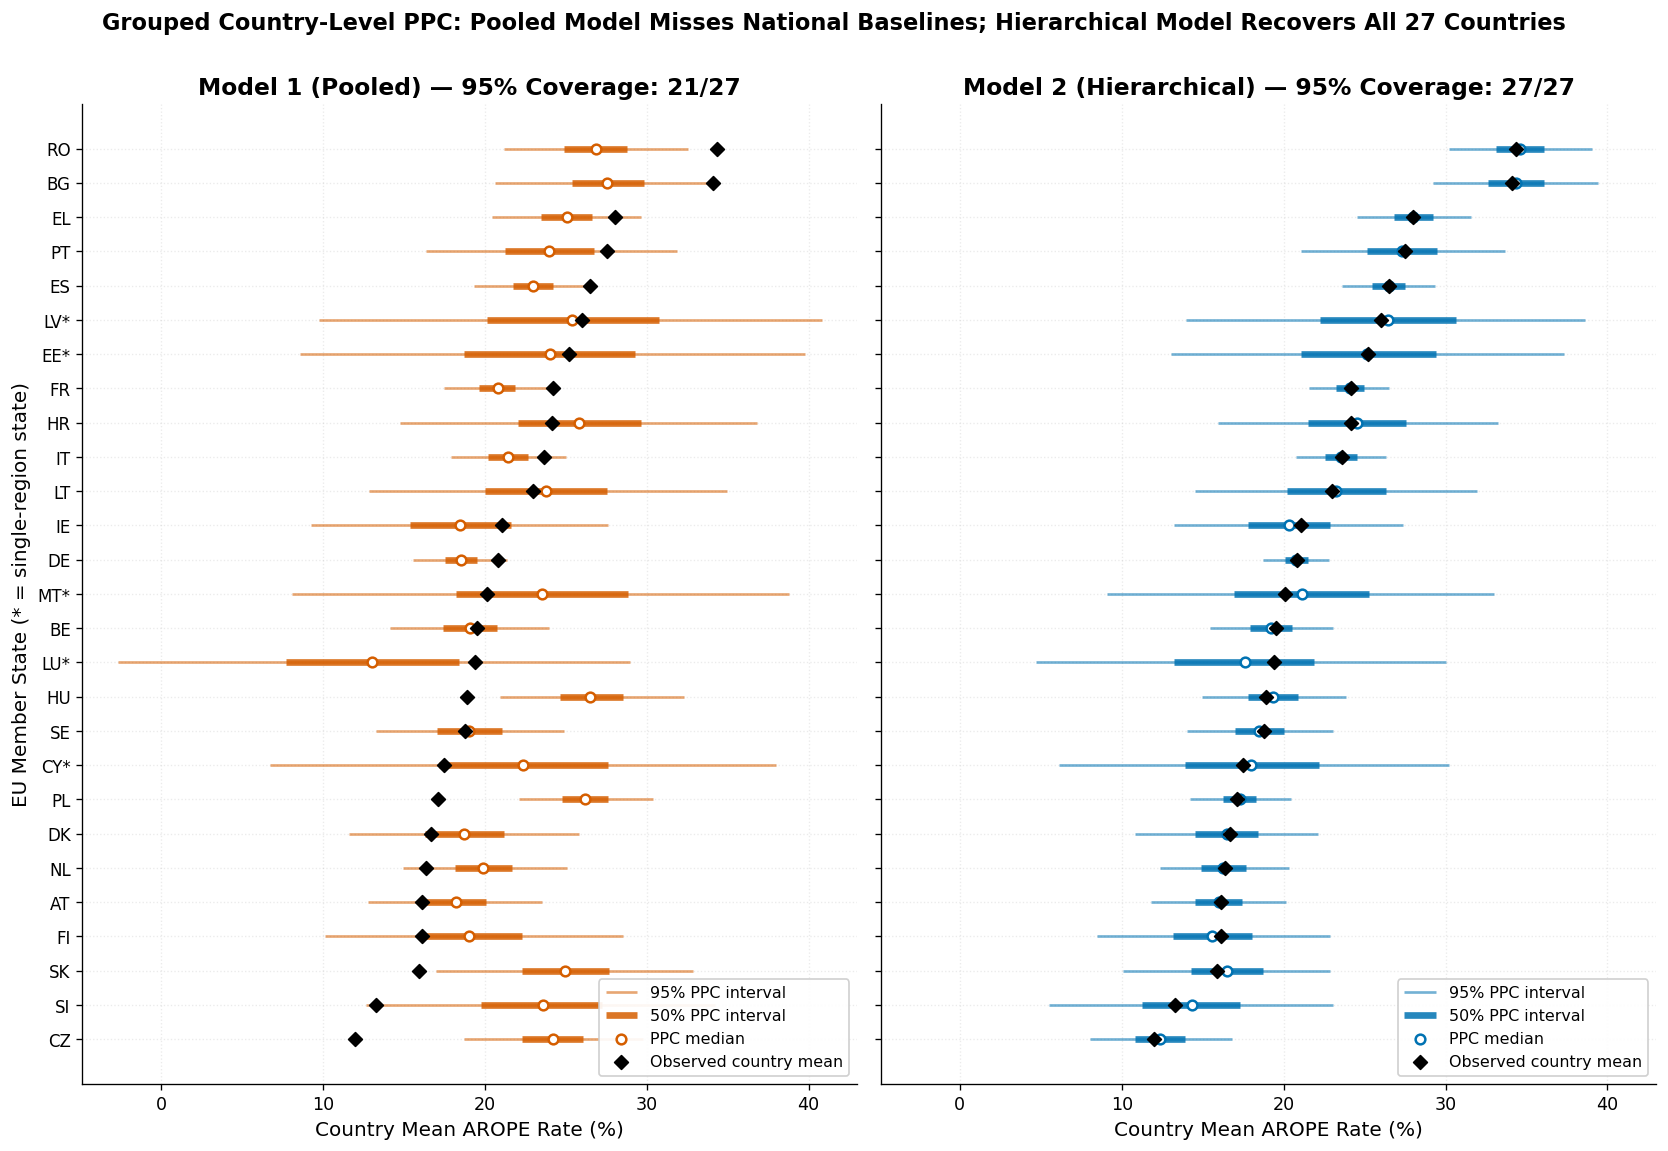

In [12]:
# Figure 07: Grouped Country-Level PPC (All 27 EU Countries, Model 1 vs. Model 2)
countries_ordered = df.groupby("country", observed=True)["arope_rate"].mean().sort_values().index.tolist()

def country_ppc_summary(yrep_flat):
    rows = []
    for c in countries_ordered:
        mask = (df["country"] == c).values
        c_means = yrep_flat[:, mask].mean(axis=1)
        obs_c = float(y_obs_pct[mask].mean())
        q025, q25, q50, q75, q975 = np.quantile(c_means, [0.025, 0.25, 0.50, 0.75, 0.975])
        rows.append((c, obs_c, q025, q25, q50, q75, q975, q025 <= obs_c <= q975))
    return pd.DataFrame(rows, columns=["country", "obs", "q025", "q25", "q50", "q75", "q975", "in_95"])

c_ppc_1 = country_ppc_summary(yrep_1_flat)
c_ppc_2 = country_ppc_summary(yrep_2_flat)

print(
    f"95% Country-Mean PPC Coverage | Model 1: {c_ppc_1['in_95'].sum()}/27 ({100*c_ppc_1['in_95'].mean():.1f}%) "
    f"| Model 2: {c_ppc_2['in_95'].sum()}/27 ({100*c_ppc_2['in_95'].mean():.1f}%)"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 9.5), sharey=True, sharex=True)
y_pos = np.arange(len(countries_ordered))

for ax, tab, title, col in [
    (axes[0], c_ppc_1, f"Model 1 (Pooled) — 95% Coverage: {c_ppc_1['in_95'].sum()}/27", PALETTE["vermilion"]),
    (axes[1], c_ppc_2, f"Model 2 (Hierarchical) — 95% Coverage: {c_ppc_2['in_95'].sum()}/27", PALETTE["blue"]),
]:
    ax.hlines(y_pos, tab["q025"], tab["q975"], color=col, lw=1.6, alpha=0.55, label="95% PPC interval")
    ax.hlines(y_pos, tab["q25"], tab["q75"], color=col, lw=4.0, alpha=0.85, label="50% PPC interval")
    ax.scatter(tab["q50"], y_pos, color="white", edgecolor=col, s=34, lw=1.5, zorder=4, label="PPC median")
    ax.scatter(tab["obs"], y_pos, color="black", marker="D", s=34, zorder=5, label="Observed country mean")
    ax.set_title(title)
    ax.set_xlabel("Country Mean AROPE Rate (%)")
    ax.legend(loc="lower right", frameon=True, framealpha=0.92, fontsize=9.5)

axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(
    [f"{c}*" if c in SINGLE_REGION_COUNTRIES else c for c in countries_ordered],
    fontsize=10,
)
axes[0].set_ylabel("EU Member State (* = single-region state)")
fig.suptitle(
    "Grouped Country-Level PPC: Pooled Model Misses National Baselines; Hierarchical Model Recovers All 27 Countries",
    fontsize=13.5, fontweight="bold", y=1.005,
)
plt.tight_layout()
save_fig(fig, "07_ppc_grouped_by_country.png")
plt.show()

## Section 6: Prior Sensitivity Analysis (All Models)

We test posterior robustness across both models against intentionally skeptical, tighter, and wider prior regimes:
- **Model 1 Sensitivity:**
  1. `M1_Base`: $\beta_{\text{inc}} \sim \mathcal{N}(0, 1.5)$
  2. `M1_Skeptical`: $\beta_{\text{inc}} \sim \mathcal{N}(0, 0.1)$ (strong prior shrinkage toward zero)
  3. `M1_Wider`: $\beta_{\text{inc}} \sim \mathcal{N}(0, 3.0)$
- **Model 2 Sensitivity:**
  1. `M2_Base`: $\mu_\beta \sim \mathcal{N}(0, 1.5)$, $\tau_\alpha, \tau_\beta \sim \text{HalfNormal}(1.0)$
  2. `M2_Skeptical_Slope`: $\mu_\beta \sim \mathcal{N}(0, 0.1)$ (tests whether data overwhelm a zero-centered skeptical belief)
  3. `M2_Tight_Hyper`: $\tau_\alpha, \tau_\beta \sim \text{HalfNormal}(0.3)$
  4. `M2_Wide_Hyper`: $\tau_\alpha, \tau_\beta \sim \text{HalfNormal}(2.0)$

All sensitivity refits are checked against the same convergence criteria ($\hat{R} \le 1.01$, Bulk/Tail ESS $> 400$, 0 divergences).

In [13]:
# Define sensitivity prior sets
SENS_PRIORS_M1 = {
    "M1_Skeptical": {**BASE_PRIORS_M1, "disposable_income_scaled": bmb.Prior("Normal", mu=0, sigma=0.1)},
    "M1_Wider": {**BASE_PRIORS_M1, "disposable_income_scaled": bmb.Prior("Normal", mu=0, sigma=3.0)},
}

SENS_PRIORS_M2 = {
    "M2_Skeptical_Slope": {**BASE_PRIORS_M2, "disposable_income_scaled": bmb.Prior("Normal", mu=0, sigma=0.1)},
    "M2_Tight_Hyper": {
        **BASE_PRIORS_M2,
        "1|country": bmb.Prior("Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=0.3)),
        "disposable_income_scaled|country": bmb.Prior("Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=0.3)),
    },
    "M2_Wide_Hyper": {
        **BASE_PRIORS_M2,
        "1|country": bmb.Prior("Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=2.0)),
        "disposable_income_scaled|country": bmb.Prior("Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=2.0)),
    },
}

sens_idatas_m1 = {"M1_Base": idata_1}
sens_idatas_m2 = {"M2_Base": idata_2}
sens_conv_rows = []

for name, pr in SENS_PRIORS_M1.items():
    m = bmb.Model(FORMULA_M1, data=df, family="gaussian", priors=pr)
    idata_s = m.fit(**MCMC_KWARGS)
    sens_idatas_m1[name] = idata_s
    sens_conv_rows.append(convergence_row(idata_s, name))

for name, pr in SENS_PRIORS_M2.items():
    m = bmb.Model(FORMULA_M2, data=df, family="gaussian", priors=pr)
    idata_s = m.fit(**MCMC_KWARGS)
    sens_idatas_m2[name] = idata_s
    sens_conv_rows.append(convergence_row(idata_s, name))

sens_conv_df = pd.DataFrame(sens_conv_rows).set_index("Model")
print("=== Convergence Verification for All Sensitivity Refits ===")
display(sens_conv_df)
assert (sens_conv_df["Status"] == "PASS").all(), "A sensitivity refit failed convergence!"

Auto-assigning NUTS sampler...


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [arope_scaled_sigma, Intercept, disposable_income_scaled, log_pop_density_scaled]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 1 seconds.


Auto-assigning NUTS sampler...


... (17 outputs left out)

NUTS: [arope_scaled_sigma, Intercept, disposable_income_scaled, log_pop_density_scaled, 1|country_sigma, 1|country_offset, disposable_income_scaled|country_sigma, disposable_income_scaled|country_offset]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 19 seconds.


=== Convergence Verification for All Sensitivity Refits ===


,Params,Max R-hat,Min Bulk-ESS,Min Tail-ESS,Divergences,Min E-BFMI,Status
Model,,,,,,,
M1_Skeptical,4,1.001,8697,5554,0,1.02,PASS
M1_Wider,4,1.001,8794,5354,0,1.01,PASS
M2_Skeptical_Slope,114,1.003,1852,3860,0,0.55,PASS
M2_Tight_Hyper,114,1.002,2669,4374,0,0.74,PASS
M2_Wide_Hyper,114,1.002,2187,3127,0,0.64,PASS


Mean                                                   \
Regime      M1_Base M1_Skeptical M1_Wider M2_Base M2_Skeptical_Slope   
Parameter                                                              
β_dens (M1)    0.04         0.01     0.04     NaN                NaN   
β_dens (M2)     NaN          NaN      NaN    0.22               0.17   
β_inc (M1)    -0.39        -0.27    -0.39     NaN                NaN   
μ_β (M2)        NaN          NaN      NaN   -1.35              -0.14   
τ_α (M2)        NaN          NaN      NaN    1.19               0.93   
τ_β (M2)        NaN          NaN      NaN    0.67               1.18   

                                                 95% HDI                  \
Regime      M2_Tight_Hyper M2_Wide_Hyper         M1_Base    M1_Skeptical   
Parameter                                                                  
β_dens (M1)            NaN           NaN   [-0.08, 0.17]   [-0.12, 0.14]   
β_dens (M2)            0.2          0.22             NaN             NaN   
β_inc (M1)             NaN           NaN  [-0.52, -0.27]  [-0.38, -0.17]   
μ_β (M2)             -1.19         -1.36             NaN             NaN   
τ_α (M2)              0.87          1.25             NaN             NaN   
τ_β (M2)              0.59          0.68             NaN             NaN   

                                                                \
Regime             M1_Wider         M2_Base M2_Skeptical_Slope   
Parameter                                                        
β_dens (M1)   [-0.08, 0.17]             NaN                NaN   
β_dens (M2)             NaN    [0.12, 0.31]       [0.07, 0.27]   
β_inc (M1)   [-0.51, -0.26]             NaN                NaN   
μ_β (M2)                NaN  [-1.83, -0.90]      [-0.33, 0.05]   
τ_α (M2)                NaN    [0.71, 1.66]       [0.56, 1.38]   
τ_β (M2)                NaN    [0.38, 1.00]       [0.79, 1.61]   

                                             
Regime       M2_Tight_Hyper   M2_Wide_Hyper  
Parameter                                    
β_dens (M1)             NaN             NaN  
β_dens (M2)    [0.10, 0.29]    [0.12, 0.31]  
β_inc (M1)              NaN             NaN  
μ_β (M2)     [-1.59, -0.79]  [-1.82, -0.87]  
τ_α (M2)       [0.60, 1.15]    [0.79, 1.81]  
τ_β (M2)       [0.37, 0.81]    [0.38, 1.03]

Saved: figures/08_prior_sensitivity.png


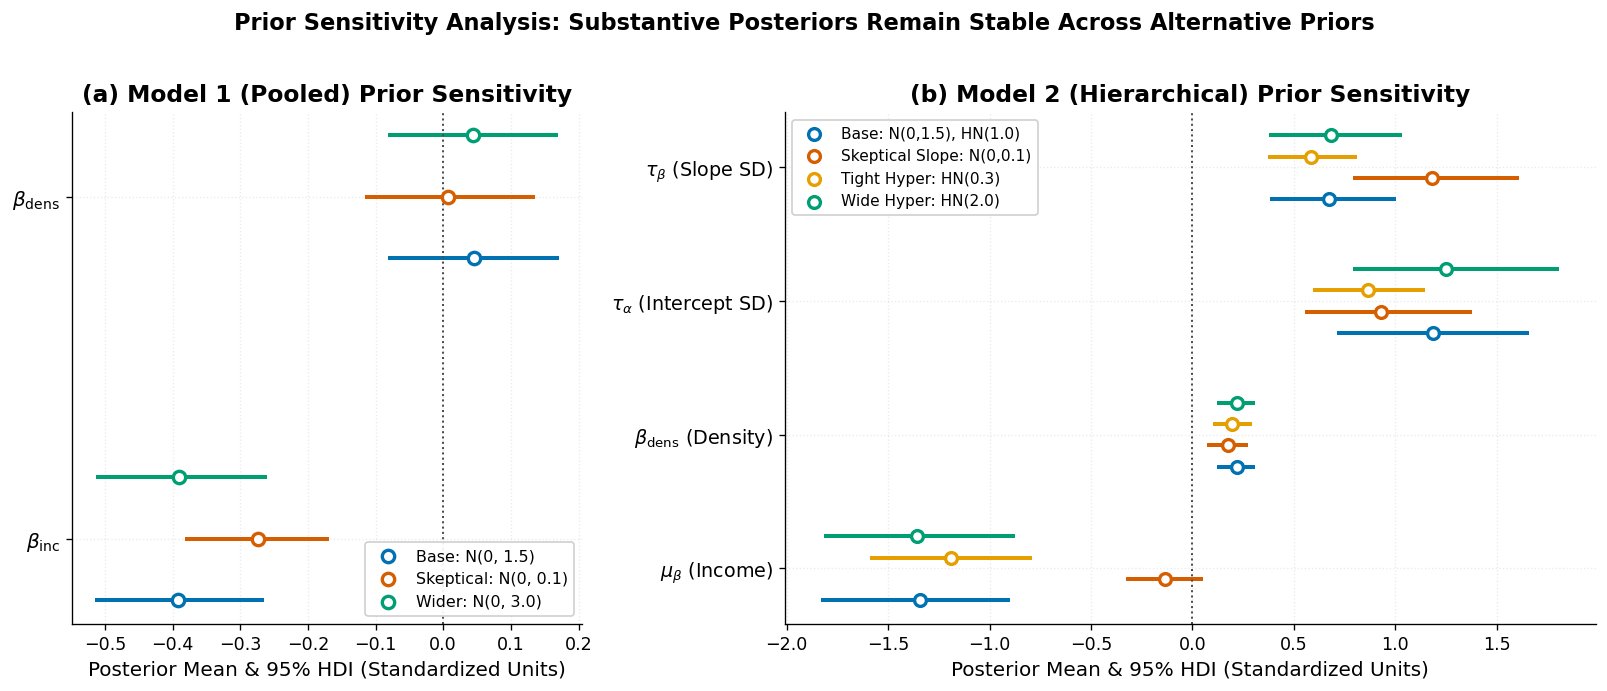

In [14]:
# Compact Prior Sensitivity Summary Table & Figure 08
def extract_param_stats(idata, var_name):
    draws = idata.posterior[var_name].values.ravel()
    hdi_lo, hdi_hi = az.hdi(draws, hdi_prob=0.95)
    return float(draws.mean()), float(draws.std()), float(hdi_lo), float(hdi_hi)

rows_sens = []
for name, id_s in sens_idatas_m1.items():
    for v, lbl in [("disposable_income_scaled", "β_inc (M1)"), ("log_pop_density_scaled", "β_dens (M1)")]:
        m, s, lo, hi = extract_param_stats(id_s, v)
        rows_sens.append({"Regime": name, "Parameter": lbl, "Mean": round(m, 2), "SD": round(s, 2), "95% HDI": f"[{lo:.2f}, {hi:.2f}]"})

for name, id_s in sens_idatas_m2.items():
    for v, lbl in [
        ("disposable_income_scaled", "μ_β (M2)"),
        ("log_pop_density_scaled", "β_dens (M2)"),
        ("1|country_sigma", "τ_α (M2)"),
        ("disposable_income_scaled|country_sigma", "τ_β (M2)"),
    ]:
        m, s, lo, hi = extract_param_stats(id_s, v)
        rows_sens.append({"Regime": name, "Parameter": lbl, "Mean": round(m, 2), "SD": round(s, 2), "95% HDI": f"[{lo:.2f}, {hi:.2f}]"})

sens_table = pd.DataFrame(rows_sens)
display(sens_table.pivot(index="Parameter", columns="Regime", values=["Mean", "95% HDI"]))

# Figure 08: Point-Interval Prior Sensitivity Plot
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw={"width_ratios": [0.85, 1.35]})

# Panel (a): Model 1 sensitivity
ax = axes[0]
m1_regimes = ["M1_Base", "M1_Skeptical", "M1_Wider"]
m1_labels = ["Base: N(0, 1.5)", "Skeptical: N(0, 0.1)", "Wider: N(0, 3.0)"]
m1_cols = [PALETTE["blue"], PALETTE["vermilion"], PALETTE["bluish_green"]]
y_offsets = [-0.18, 0.0, 0.18]
m1_params = [("disposable_income_scaled", r"$\beta_{\mathrm{inc}}$"), ("log_pop_density_scaled", r"$\beta_{\mathrm{dens}}$")]

for p_idx, (v, plbl) in enumerate(m1_params):
    for r_idx, (rname, rlbl, col) in enumerate(zip(m1_regimes, m1_labels, m1_cols)):
        m, s, lo, hi = extract_param_stats(sens_idatas_m1[rname], v)
        y = p_idx + y_offsets[r_idx]
        ax.hlines(y, lo, hi, color=col, lw=2.4)
        ax.scatter(m, y, color="white", edgecolor=col, s=55, lw=2.0, zorder=4, label=rlbl if p_idx == 0 else None)

ax.axvline(0, color=PALETTE["slate"], ls=":", lw=1.2)
ax.set_yticks([0, 1])
ax.set_yticklabels([p[1] for p in m1_params], fontsize=12)
ax.set_xlabel("Posterior Mean & 95% HDI (Standardized Units)")
ax.set_title("(a) Model 1 (Pooled) Prior Sensitivity")
ax.legend(loc="lower right", frameon=True, framealpha=0.92, fontsize=9.5)

# Panel (b): Model 2 sensitivity
ax = axes[1]
m2_regimes = ["M2_Base", "M2_Skeptical_Slope", "M2_Tight_Hyper", "M2_Wide_Hyper"]
m2_labels = ["Base: N(0,1.5), HN(1.0)", "Skeptical Slope: N(0,0.1)", "Tight Hyper: HN(0.3)", "Wide Hyper: HN(2.0)"]
m2_cols = [PALETTE["blue"], PALETTE["vermilion"], PALETTE["orange"], PALETTE["bluish_green"]]
y_offsets_m2 = [-0.24, -0.08, 0.08, 0.24]
m2_params = [
    ("disposable_income_scaled", r"$\mu_\beta$ (Income)"),
    ("log_pop_density_scaled", r"$\beta_{\mathrm{dens}}$ (Density)"),
    ("1|country_sigma", r"$\tau_\alpha$ (Intercept SD)"),
    ("disposable_income_scaled|country_sigma", r"$\tau_\beta$ (Slope SD)"),
]

for p_idx, (v, plbl) in enumerate(m2_params):
    for r_idx, (rname, rlbl, col) in enumerate(zip(m2_regimes, m2_labels, m2_cols)):
        m, s, lo, hi = extract_param_stats(sens_idatas_m2[rname], v)
        y = p_idx + y_offsets_m2[r_idx]
        ax.hlines(y, lo, hi, color=col, lw=2.4)
        ax.scatter(m, y, color="white", edgecolor=col, s=50, lw=2.0, zorder=4, label=rlbl if p_idx == 0 else None)

ax.axvline(0, color=PALETTE["slate"], ls=":", lw=1.2)
ax.set_yticks(range(len(m2_params)))
ax.set_yticklabels([p[1] for p in m2_params], fontsize=11.5)
ax.set_xlabel("Posterior Mean & 95% HDI (Standardized Units)")
ax.set_title("(b) Model 2 (Hierarchical) Prior Sensitivity")
ax.legend(loc="upper left", frameon=True, framealpha=0.92, fontsize=9.2)

fig.suptitle(
    "Prior Sensitivity Analysis: Substantive Posteriors Remain Stable Across Alternative Priors",
    fontsize=13.5, fontweight="bold", y=1.02,
)
plt.tight_layout()
save_fig(fig, "08_prior_sensitivity.png")
plt.show()

## Section 7: Model Comparison (PSIS-LOO-CV & Practical Predictive Performance)

We compare out-of-sample predictive accuracy via Pareto-Smoothed Importance Sampling Leave-One-Out Cross-Validation (**PSIS-LOO-CV**), inspect pointwise Pareto $\hat{k}$ reliability diagnostics, evaluate a conditional **Student-$t$ hierarchical robustness check** (`family="t"`, $\nu \sim \text{Gamma}(2, 0.1)$) to test whether any $\hat{k} > 0.7$ observations reflect heavy-tailed residual misspecification versus structural single-region leverage, and report practical predictive metrics (**RMSE**, **MAE** in real AROPE percentage points, and **Bayesian $R^2$**).

In [15]:
# 1. PSIS-LOO-CV Comparison (Model 1 vs. Model 2)
loo_1 = az.loo(idata_1, pointwise=True)
loo_2 = az.loo(idata_2, pointwise=True)

cmp_12 = az.compare({"M1_Pooled": idata_1, "M2_Hierarchical": idata_2}, ic="loo")
print("=== PSIS-LOO-CV Model Comparison (Primary Models) ===")
display(cmp_12[["rank", "elpd_loo", "p_loo", "elpd_diff", "dse", "weight", "warning"]].round(2))

# Inspect Pareto k diagnostics for both models
k1 = loo_1.pareto_k.values
k2 = loo_2.pareto_k.values
print(f"Model 1 Pareto k | > 0.5: {int(np.sum(k1 > 0.5))}/232 | > 0.7: {int(np.sum(k1 > 0.7))}/232 | max k = {k1.max():.2f}")
print(f"Model 2 Pareto k | > 0.5: {int(np.sum(k2 > 0.5))}/232 | > 0.7: {int(np.sum(k2 > 0.7))}/232 | max k = {k2.max():.2f}")

high_k_df = df.loc[k2 > 0.7, ["geo", "country", "arope_rate", "disposable_income"]].copy()
high_k_df["pareto_k"] = np.round(k2[k2 > 0.7], 2)
high_k_df["country_n"] = high_k_df["country"].map(df["country"].value_counts())
high_k_df = high_k_df.sort_values("pareto_k", ascending=False)
print("\nModel 2 Observations with Pareto k > 0.7:")
display(high_k_df)

/Users/cmanzano/Documents/Aalto_exit/BDA/Workspace/bda_project/lib/python3.9/site-packages/arviz/stats/stats.py:789: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.7 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


=== PSIS-LOO-CV Model Comparison (Primary Models) ===


/Users/cmanzano/Documents/Aalto_exit/BDA/Workspace/bda_project/lib/python3.9/site-packages/arviz/stats/stats.py:789: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.7 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,rank,elpd_loo,p_loo,elpd_diff,dse,weight,warning
M2_Hierarchical,0,-208.37,35.45,0.00,0.00,0.99,True
M1_Pooled,1,-315.22,4.91,106.85,12.99,0.01,False


Model 1 Pareto k | > 0.5: 0/232 | > 0.7: 0/232 | max k = 0.35
Model 2 Pareto k | > 0.5: 22/232 | > 0.7: 4/232 | max k = 1.09

Model 2 Observations with Pareto k > 0.7:


,geo,country,arope_rate,disposable_income,pareto_k,country_n
176,LU00,LU,19.4,37700.0,1.09,1
178,MT00,MT,20.1,17200.0,0.94,1
78,EE00,EE,25.2,13600.0,0.84,1
177,LV00,LV,26.0,10600.0,0.72,1


In [16]:
# Conditional Student-t Robustness Check (Triggered by Pareto k > 0.7 on FRY3 & small-group countries)
PRIORS_M3_T = {**BASE_PRIORS_M2, "nu": bmb.Prior("Gamma", alpha=2.0, beta=0.1)}
model_3_t = bmb.Model(FORMULA_M2, data=df, family="t", priors=PRIORS_M3_T)
print("=== Student-t Hierarchical Robustness Check (Model 2-t) ===")
print(model_3_t)

idata_3_t = fit_and_sample_ppc(model_3_t, "Model 2-t (Student-t Check)", **MCMC_KWARGS)
conv_m3 = pd.DataFrame([convergence_row(idata_3_t, "Model 2-t (Student-t)")]).set_index("Model")
display(conv_m3)

nu_var = "nu" if "nu" in idata_3_t.posterior else "arope_scaled_nu"
nu_draws = idata_3_t.posterior[nu_var].values.ravel()
nu_lo, nu_hi = az.hdi(nu_draws, hdi_prob=0.95)
print(f"Posterior degrees of freedom ν: mean = {nu_draws.mean():.1f}, SD = {nu_draws.std():.1f}, 95% HDI = [{nu_lo:.1f}, {nu_hi:.1f}]")

loo_3_t = az.loo(idata_3_t, pointwise=True)
k3 = loo_3_t.pareto_k.values
print(f"Model 2-t Pareto k | > 0.5: {int(np.sum(k3 > 0.5))}/232 | > 0.7: {int(np.sum(k3 > 0.7))}/232 | max k = {k3.max():.2f}")

cmp_all = az.compare(
    {"M1_Pooled": idata_1, "M2_Hierarchical": idata_2, "M2t_StudentT": idata_3_t},
    ic="loo",
)
print("\n=== PSIS-LOO-CV Comparison Including Student-t Check ===")
display(cmp_all[["rank", "elpd_loo", "p_loo", "elpd_diff", "dse", "weight", "warning"]].round(2))

=== Student-t Hierarchical Robustness Check (Model 2-t) ===
       Formula: arope_scaled ~ disposable_income_scaled + log_pop_density_scaled + (1 + disposable_income_scaled | country)
        Family: t
          Link: mu = identity
  Observations: 232
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 0.0, sigma: 1.5)
            disposable_income_scaled ~ Normal(mu: 0.0, sigma: 1.5)
            log_pop_density_scaled ~ Normal(mu: 0.0, sigma: 1.0)
        
        Group-level effects
            1|country ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 1.0))
            disposable_income_scaled|country ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 1.0))
        
        Auxiliary parameters
            sigma ~ Exponential(lam: 1.0)
            nu ~ Gamma(alpha: 2.0, beta: 0.1)
Sampling Model 2-t (Student-t Check) (4 chains x 2000 draws, tune=1000, target_accept=0.95)...


Auto-assigning NUTS sampler...


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [arope_scaled_sigma, arope_scaled_nu, Intercept, disposable_income_scaled, log_pop_density_scaled, 1|country_sigma, 1|country_offset, disposable_income_scaled|country_sigma, disposable_income_scaled|country_offset]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 20 seconds.


... (3 outputs left out)

/Users/cmanzano/Documents/Aalto_exit/BDA/Workspace/bda_project/lib/python3.9/site-packages/arviz/stats/stats.py:789: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.7 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(



=== PSIS-LOO-CV Comparison Including Student-t Check ===


/Users/cmanzano/Documents/Aalto_exit/BDA/Workspace/bda_project/lib/python3.9/site-packages/arviz/stats/stats.py:789: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.7 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/Users/cmanzano/Documents/Aalto_exit/BDA/Workspace/bda_project/lib/python3.9/site-packages/arviz/stats/stats.py:789: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.7 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  w

,rank,elpd_loo,p_loo,elpd_diff,dse,weight,warning
M2_Hierarchical,0,-208.37,35.45,0.00,0.00,0.99,True
M2t_StudentT,1,-210.17,38.50,1.80,1.22,0.00,True
M1_Pooled,2,-315.22,4.91,106.85,12.99,0.01,False


Saved: figures/09_loo_pareto_k.png


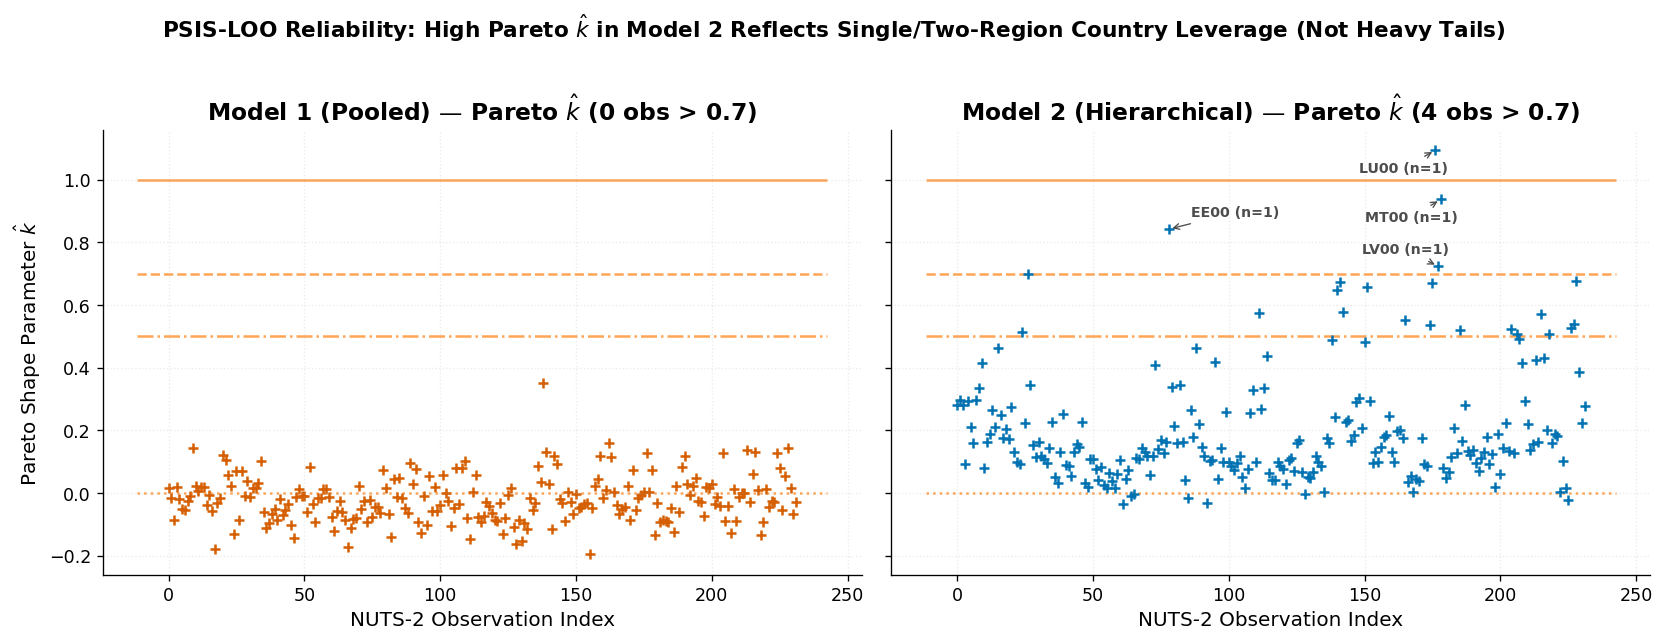

In [17]:
# Figure 09: Pareto k Diagnostic Plots (Model 1 vs. Model 2)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)

az.plot_khat(loo_1, ax=axes[0], color=PALETTE["vermilion"], show_hlines=True)
axes[0].set_title(f"Model 1 (Pooled) — Pareto $\hat{{k}}$ (0 obs > 0.7)")
axes[0].set_xlabel("NUTS-2 Observation Index")
axes[0].set_ylabel("Pareto Shape Parameter $\hat{k}$")

az.plot_khat(loo_2, ax=axes[1], color=PALETTE["blue"], show_hlines=True)
axes[1].set_title(f"Model 2 (Hierarchical) — Pareto $\hat{{k}}$ ({int(np.sum(k2 > 0.7))} obs > 0.7)")
axes[1].set_xlabel("NUTS-2 Observation Index")
axes[1].set_ylabel("")

# Annotate observations with k > 0.7 in Model 2
high_idx = np.where(k2 > 0.7)[0]
for rank_i, idx in enumerate(high_idx):
    geo_lbl = df.loc[idx, "geo"]
    n_j = int(country_counts[df.loc[idx, "country"]])
    y_shift = 0.04 if rank_i % 2 == 0 else -0.07
    x_shift = -28 if idx > 165 else 8
    axes[1].annotate(
        f"{geo_lbl} (n={n_j})",
        xy=(idx, k2[idx]),
        xytext=(idx + x_shift, k2[idx] + y_shift),
        fontsize=8.5,
        fontweight="bold",
        color=PALETTE["slate"],
        arrowprops=dict(arrowstyle="->", color=PALETTE["slate"], lw=0.8),
    )

fig.suptitle(
    "PSIS-LOO Reliability: High Pareto $\hat{k}$ in Model 2 Reflects Single/Two-Region Country Leverage (Not Heavy Tails)",
    fontsize=13, fontweight="bold", y=1.02,
)
plt.tight_layout()
save_fig(fig, "09_loo_pareto_k.png")
plt.show()

In [18]:
# Practical Predictive Performance: RMSE, MAE (in Real AROPE %) & Bayesian R^2
def compute_posterior_mu_pct(idata, is_hierarchical: bool) -> np.ndarray:
    post = idata.posterior
    b0 = post["Intercept"].values.reshape(-1, 1)
    b_inc = post["disposable_income_scaled"].values.reshape(-1, 1)
    b_dens = post["log_pop_density_scaled"].values.reshape(-1, 1)

    x_inc = df["disposable_income_scaled"].values[None, :]
    x_dens = df["log_pop_density_scaled"].values[None, :]

    if not is_hierarchical:
        mu_z = b0 + b_inc * x_inc + b_dens * x_dens
    else:
        c_levels = list(post["1|country"].coords["country__factor_dim"].values)
        c_idx = df["country"].astype(str).map({c: i for i, c in enumerate(c_levels)}).values
        u0 = post["1|country"].values.reshape(-1, len(c_levels))[:, c_idx]
        u1 = post["disposable_income_scaled|country"].values.reshape(-1, len(c_levels))[:, c_idx]
        mu_z = (b0 + u0) + (b_inc + u1) * x_inc + b_dens * x_dens

    return mu_z * AROPE_SD + AROPE_MEAN


mu_1_pct = compute_posterior_mu_pct(idata_1, is_hierarchical=False)
mu_2_pct = compute_posterior_mu_pct(idata_2, is_hierarchical=True)

def practical_metrics(mu_pct, yrep_flat, model_name):
    # Posterior mean prediction error (pointwise RMSE/MAE)
    pred_mean = mu_pct.mean(axis=0)
    rmse_mean = float(np.sqrt(np.mean((y_obs_pct - pred_mean) ** 2)))
    mae_mean = float(np.mean(np.abs(y_obs_pct - pred_mean)))

    # Posterior predictive draw-averaged RMSE/MAE (includes residual noise)
    rmse_pp = float(np.sqrt(np.mean((yrep_flat - y_obs_pct[None, :]) ** 2, axis=1)).mean())
    mae_pp = float(np.mean(np.abs(yrep_flat - y_obs_pct[None, :]), axis=1).mean())

    # Bayesian R^2 (Gelman et al., 2019 via ArviZ on posterior expected values mu)
    r2_res = az.r2_score(y_obs_pct, mu_pct)
    return {
        "Model": model_name,
        "RMSE (E[y|θ], pp)": round(rmse_mean, 2),
        "MAE (E[y|θ], pp)": round(mae_mean, 2),
        "PPC RMSE (y_rep, pp)": round(rmse_pp, 2),
        "PPC MAE (y_rep, pp)": round(mae_pp, 2),
        "Bayesian R²": f"{r2_res['r2']:.2f} ± {r2_res['r2_std']:.2f}",
    }


metrics_df = pd.DataFrame([
    practical_metrics(mu_1_pct, yrep_1_flat, "Model 1 (Pooled)"),
    practical_metrics(mu_2_pct, yrep_2_flat, "Model 2 (Hierarchical)"),
]).set_index("Model")
print("=== Practical Predictive Performance (Original AROPE Percentage Points) ===")
display(metrics_df)

=== Practical Predictive Performance (Original AROPE Percentage Points) ===


,"RMSE (E[y|θ], pp)","MAE (E[y|θ], pp)","PPC RMSE (y_rep, pp)","PPC MAE (y_rep, pp)",Bayesian R²
Model,,,,,
Model 1 (Pooled),7.79,6.00,11.10,8.82,0.15 ± 0.04
Model 2 (Hierarchical),4.18,3.34,6.44,5.15,0.71 ± 0.02


## Section 8: Substantive Results, Partial Pooling & Interpretation

We translate the Model 2 posterior into domain-relevant European policy units:
- **Back-transformation of income slopes:** A +€1,000 increase in regional disposable income equals $+1000 / \text{SD}_{\text{inc}}$ standardized units, producing an AROPE change of:
  $$\Delta\text{AROPE}_{\text{pp per €1k}} = \beta_{\text{inc}, j} \times \frac{\text{SD}_{\text{AROPE}}}{\text{SD}_{\text{inc}}} \times 1000$$
- All intervals below report **95% Highest Density Intervals (95% HDI)** alongside 50% inner intervals for visual clarity.

In [19]:
# 1. Population-Level Summary Table (Standardized & Back-Transformed Real Units)
SLOPE_TO_PP_PER_1K = (AROPE_SD / INC_SD) * 1000.0

post2 = idata_2.posterior
pop_rows = []

param_specs = [
    ("Intercept", "Global Intercept (μ_α)", lambda x: x * AROPE_SD + AROPE_MEAN, "AROPE % at avg. covariates"),
    ("disposable_income_scaled", "Global Income Slope (μ_β)", lambda x: x * SLOPE_TO_PP_PER_1K, "pp AROPE per +€1,000"),
    ("log_pop_density_scaled", "Urbanization Slope (β_dens)", lambda x: x * AROPE_SD * np.log(2.0) / LOG_DENS_SD, "pp AROPE per 2x pop. density"),
    ("1|country_sigma", "Country Intercept SD (τ_α)", lambda x: x * AROPE_SD, "pp AROPE across countries"),
    ("disposable_income_scaled|country_sigma", "Country Slope SD (τ_β)", lambda x: x * SLOPE_TO_PP_PER_1K, "pp per +€1,000 across countries"),
    (SIGMA_VAR, "Residual SD (σ)", lambda x: x * AROPE_SD, "pp AROPE within countries"),
]

for var, label, fn_real, unit_real in param_specs:
    z_draws = post2[var].values.ravel()
    z_lo, z_hi = az.hdi(z_draws, hdi_prob=0.95)
    r_draws = fn_real(z_draws)
    r_lo, r_hi = az.hdi(r_draws, hdi_prob=0.95)
    pop_rows.append({
        "Parameter": label,
        "Std. Mean (SD)": f"{z_draws.mean():.2f} ({z_draws.std():.2f})",
        "Std. 95% HDI": f"[{z_lo:.2f}, {z_hi:.2f}]",
        "Real-Unit Mean (SD)": f"{r_draws.mean():.2f} ({r_draws.std():.2f})",
        "Real-Unit 95% HDI": f"[{r_lo:.2f}, {r_hi:.2f}]",
        "Real Unit": unit_real,
    })

pop_summary_df = pd.DataFrame(pop_rows).set_index("Parameter")
print("=== Model 2 Population-Level Posterior Summary (95% HDI) ===")
display(pop_summary_df)

=== Model 2 Population-Level Posterior Summary (95% HDI) ===


,Std. Mean (SD),Std. 95% HDI,Real-Unit Mean (SD),Real-Unit 95% HDI,Real Unit
Parameter,,,,,
Global Intercept (μ_α),-0.37 (0.25),"[-0.86, 0.14]",18.78 (2.15),"[14.58, 23.02]",AROPE % at avg. covariates
Global Income Slope (μ_β),-1.35 (0.24),"[-1.83, -0.90]",-1.63 (0.29),"[-2.22, -1.09]","pp AROPE per +€1,000"
Urbanization Slope (β_dens),0.22 (0.05),"[0.12, 0.31]",1.10 (0.24),"[0.62, 1.55]",pp AROPE per 2x pop. density
Country Intercept SD (τ_α),1.19 (0.24),"[0.71, 1.66]",10.02 (2.05),"[6.03, 13.99]",pp AROPE across countries
Country Slope SD (τ_β),0.67 (0.16),"[0.38, 1.00]",0.82 (0.20),"[0.46, 1.22]","pp per +€1,000 across countries"
Residual SD (σ),0.54 (0.03),"[0.49, 0.60]",4.57 (0.24),"[4.10, 5.04]",pp AROPE within countries


Saved: figures/10_country_slopes_caterpillar.png


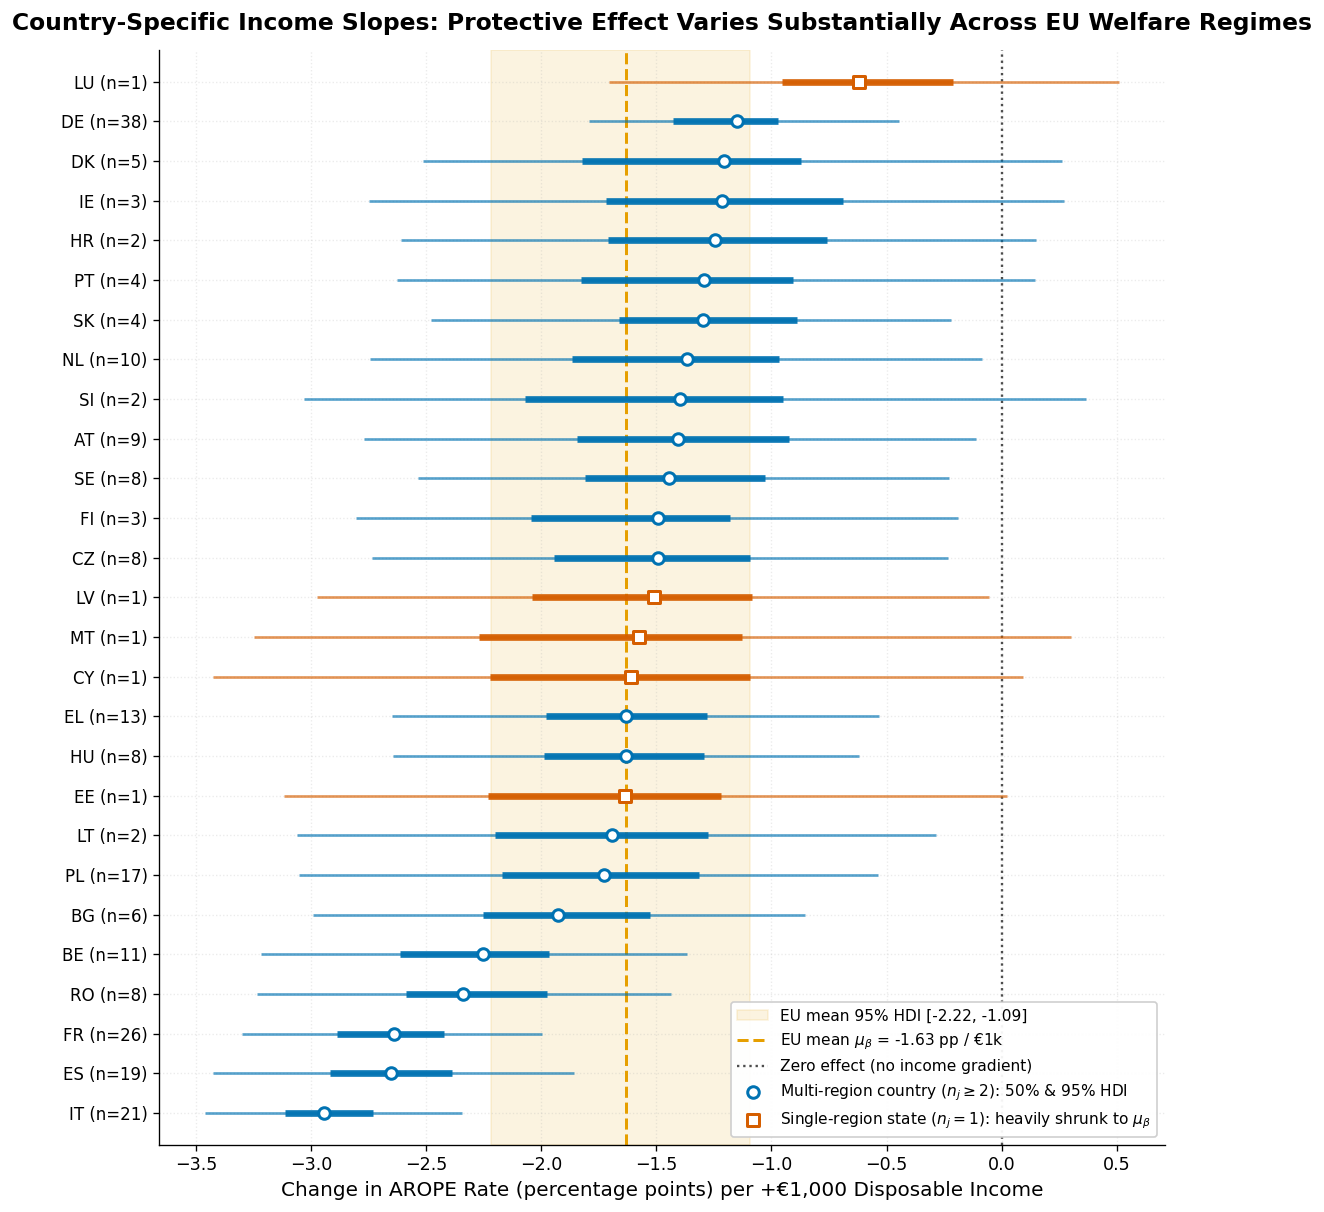

Steepest income gradients (most protective per +€1,000):


,country,n_j,mean,h95_lo,h95_hi,p_neg
0,IT,21,-2.95,-3.46,-2.34,1.0
1,ES,19,-2.65,-3.43,-1.86,1.0
2,FR,26,-2.64,-3.30,-2.00,1.0
3,RO,8,-2.34,-3.23,-1.44,1.0
4,BE,11,-2.26,-3.22,-1.37,1.0


Flattest income gradients (weakest regional income slope):


,country,n_j,mean,h95_lo,h95_hi,p_neg
22,HR,2,-1.24,-2.61,0.15,0.96
23,IE,3,-1.22,-2.75,0.27,0.94
24,DK,5,-1.21,-2.51,0.26,0.95
25,DE,38,-1.15,-1.79,-0.44,1.00
26,LU,1,-0.62,-1.71,0.51,0.87


In [20]:
# Figure 10 (Hero Figure): Country-Specific Income Slopes Across All 27 EU Countries (pp per +€1,000)
c_levels = list(post2["disposable_income_scaled|country"].coords["country__factor_dim"].values)
pop_slope_pp = post2["disposable_income_scaled"].values.ravel() * SLOPE_TO_PP_PER_1K
eu_mean_pp = float(pop_slope_pp.mean())
eu_hdi_lo, eu_hdi_hi = az.hdi(pop_slope_pp, hdi_prob=0.95)

total_slopes_z = (
    post2["disposable_income_scaled"].values[:, :, None]
    + post2["disposable_income_scaled|country"].values
).reshape(-1, len(c_levels))
total_slopes_pp = total_slopes_z * SLOPE_TO_PP_PER_1K

slope_rows = []
for i, c in enumerate(c_levels):
    d = total_slopes_pp[:, i]
    h95_lo, h95_hi = az.hdi(d, hdi_prob=0.95)
    h50_lo, h50_hi = az.hdi(d, hdi_prob=0.50)
    slope_rows.append({
        "country": c,
        "n_j": int(country_counts[c]),
        "is_single": c in SINGLE_REGION_COUNTRIES,
        "mean": float(d.mean()),
        "median": float(np.median(d)),
        "h50_lo": float(h50_lo),
        "h50_hi": float(h50_hi),
        "h95_lo": float(h95_lo),
        "h95_hi": float(h95_hi),
        "p_neg": float(np.mean(d < 0)),
    })

slopes_df = pd.DataFrame(slope_rows).sort_values("mean", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.5, 10.2))
y_pos = np.arange(len(slopes_df))

ax.axvspan(eu_hdi_lo, eu_hdi_hi, color=PALETTE["orange"], alpha=0.12, zorder=1,
           label=f"EU mean 95% HDI [{eu_hdi_lo:.2f}, {eu_hdi_hi:.2f}]")
ax.axvline(eu_mean_pp, color=PALETTE["orange"], ls="--", lw=1.8, zorder=2,
           label=rf"EU mean $\mu_\beta$ = {eu_mean_pp:.2f} pp / €1k")
ax.axvline(0.0, color=PALETTE["slate"], ls=":", lw=1.4, zorder=2, label="Zero effect (no income gradient)")

for idx, row in slopes_df.iterrows():
    col = PALETTE["vermilion"] if row["is_single"] else PALETTE["blue"]
    marker = "s" if row["is_single"] else "o"
    ax.hlines(idx, row["h95_lo"], row["h95_hi"], color=col, lw=1.6, alpha=0.65, zorder=3)
    ax.hlines(idx, row["h50_lo"], row["h50_hi"], color=col, lw=4.0, alpha=0.95, zorder=4)
    ax.scatter(row["mean"], idx, color="white", edgecolor=col, marker=marker, s=48, lw=1.8, zorder=5)

# Proxy legend markers for multi-region vs single-region
ax.scatter([], [], color="white", edgecolor=PALETTE["blue"], marker="o", s=48, lw=1.8,
           label=r"Multi-region country ($n_j \geq 2$): 50% & 95% HDI")
ax.scatter([], [], color="white", edgecolor=PALETTE["vermilion"], marker="s", s=48, lw=1.8,
           label=r"Single-region state ($n_j = 1$): heavily shrunk to $\mu_\beta$")

ax.set_yticks(y_pos)
ax.set_yticklabels([f"{r['country']} (n={r['n_j']})" for _, r in slopes_df.iterrows()], fontsize=10)
ax.set_ylim(-0.8, len(slopes_df) - 0.2)
ax.set_xlabel("Change in AROPE Rate (percentage points) per +€1,000 Disposable Income")
ax.set_title(
    "Country-Specific Income Slopes: Protective Effect Varies Substantially Across EU Welfare Regimes",
    pad=12,
)
ax.legend(loc="lower right", frameon=True, framealpha=0.94, fontsize=9.2)
plt.tight_layout()
save_fig(fig, "10_country_slopes_caterpillar.png")
plt.show()

# Print top 5 steepest & 5 flattest countries
print("Steepest income gradients (most protective per +€1,000):")
display(slopes_df.head(5)[["country", "n_j", "mean", "h95_lo", "h95_hi", "p_neg"]].round(2))
print("Flattest income gradients (weakest regional income slope):")
display(slopes_df.tail(5)[["country", "n_j", "mean", "h95_lo", "h95_hi", "p_neg"]].round(2))

Saved: figures/11_partial_pooling_shrinkage.png


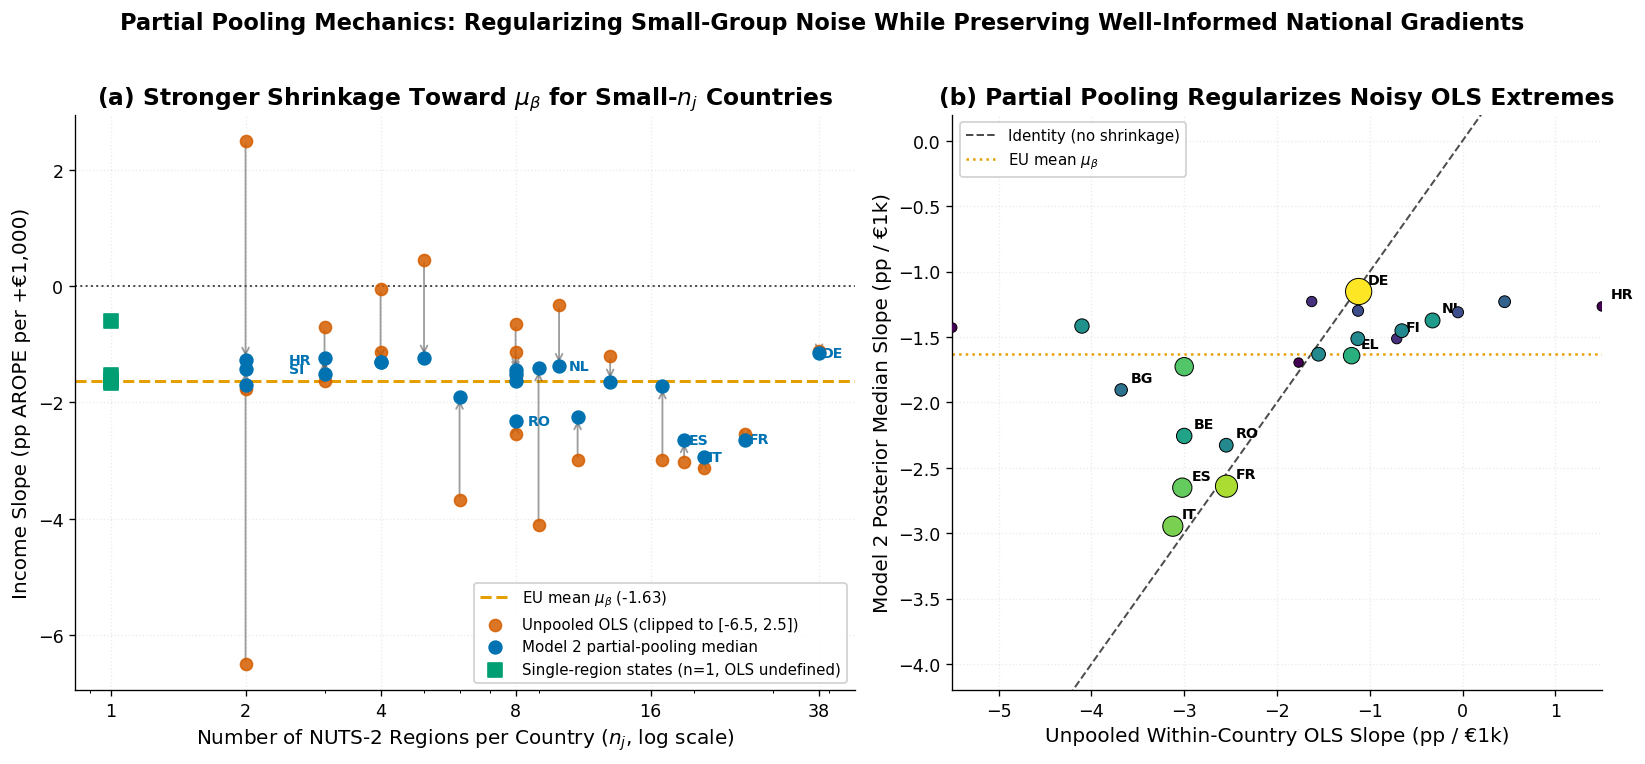

In [21]:
# Figure 11: Partial Pooling Shrinkage (Unpooled Within-Country OLS vs. Model 2 Posterior Medians)
ols_rows = []
for c in c_levels:
    sub = df[df["country"] == c]
    n_j = len(sub)
    if n_j >= 2 and sub["disposable_income"].nunique() > 1:
        # Unpooled within-country OLS slope (pp per +€1,000)
        b1_ols = float(np.polyfit(sub["disposable_income"].values / 1000.0, sub["arope_rate"].values, 1)[0])
    else:
        b1_ols = np.nan
    m2_med = float(slopes_df.loc[slopes_df["country"] == c, "median"].iloc[0])
    ols_rows.append({"country": c, "n_j": n_j, "ols_pp": b1_ols, "m2_med_pp": m2_med})

shrink_df = pd.DataFrame(ols_rows).sort_values("n_j", ascending=True).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(13.8, 6.2), gridspec_kw={"width_ratios": [1.2, 1.0]})

# Panel (a): Shrinkage arrows from unpooled OLS -> Model 2 partial pooling vs. sample size n_j
ax = axes[0]
multi = shrink_df.dropna(subset=["ols_pp"]).copy()
# Clip extreme 2-region OLS visual display while annotating true value if outside bounds
clip_lo, clip_hi = -6.5, 2.5
ax.axhline(eu_mean_pp, color=PALETTE["orange"], ls="--", lw=1.8, label=rf"EU mean $\mu_\beta$ ({eu_mean_pp:.2f})")
ax.axhline(0, color=PALETTE["slate"], ls=":", lw=1.2)

for _, r in multi.iterrows():
    y_ols = np.clip(r["ols_pp"], clip_lo, clip_hi)
    ax.annotate(
        "",
        xy=(r["n_j"], r["m2_med_pp"]),
        xytext=(r["n_j"], y_ols),
        arrowprops=dict(arrowstyle="->", color=PALETTE["slate"], alpha=0.55, lw=1.1),
    )

ax.scatter(multi["n_j"], np.clip(multi["ols_pp"], clip_lo, clip_hi), color=PALETTE["vermilion"],
           s=52, alpha=0.85, zorder=4, label="Unpooled OLS (clipped to [-6.5, 2.5])")
ax.scatter(multi["n_j"], multi["m2_med_pp"], color=PALETTE["blue"],
           s=58, zorder=5, label="Model 2 partial-pooling median")

# Single-region countries (OLS undefined)
singles = shrink_df[shrink_df["n_j"] == 1]
ax.scatter(singles["n_j"], singles["m2_med_pp"], color=PALETTE["bluish_green"], marker="s",
           s=70, zorder=6, label="Single-region states (n=1, OLS undefined)")

for _, r in multi.iterrows():
    if r["ols_pp"] < clip_lo or r["ols_pp"] > clip_hi or r["country"] in ["RO", "ES", "IT", "DE", "NL", "FR", "HR"]:
        ax.text(r["n_j"] + 0.5, r["m2_med_pp"], r["country"], fontsize=8.5, va="center", color=PALETTE["blue"], fontweight="bold")

ax.set_xscale("log")
ax.set_xticks([1, 2, 4, 8, 16, 38])
ax.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
ax.set_xlabel("Number of NUTS-2 Regions per Country ($n_j$, log scale)")
ax.set_ylabel("Income Slope (pp AROPE per +€1,000)")
ax.set_title(r"(a) Stronger Shrinkage Toward $\mu_\beta$ for Small-$n_j$ Countries")
ax.legend(loc="lower right", frameon=True, framealpha=0.92, fontsize=9.0)

# Panel (b): Direct OLS vs. Model 2 comparison for multi-region countries
ax = axes[1]
lim_lo, lim_hi = -5.5, 1.5
ax.plot([lim_lo, lim_hi], [lim_lo, lim_hi], color=PALETTE["slate"], ls="--", lw=1.2, label="Identity (no shrinkage)")
ax.axhline(eu_mean_pp, color=PALETTE["orange"], ls=":", lw=1.5, label=r"EU mean $\mu_\beta$")
sc = ax.scatter(
    np.clip(multi["ols_pp"], lim_lo, lim_hi),
    multi["m2_med_pp"],
    c=np.log(multi["n_j"]),
    cmap="viridis",
    s=20 + 6 * multi["n_j"],
    edgecolor="black",
    lw=0.6,
    zorder=4,
)
for _, r in multi.iterrows():
    if r["country"] in ["RO", "ES", "IT", "DE", "NL", "FR", "BE", "FI", "HR", "BG", "EL"]:
        ax.text(np.clip(r["ols_pp"], lim_lo, lim_hi) + 0.1, r["m2_med_pp"] + 0.06, r["country"], fontsize=8.5, fontweight="bold")
ax.set_xlim(lim_lo, lim_hi)
ax.set_ylim(-4.2, 0.2)
ax.set_xlabel("Unpooled Within-Country OLS Slope (pp / €1k)")
ax.set_ylabel("Model 2 Posterior Median Slope (pp / €1k)")
ax.set_title("(b) Partial Pooling Regularizes Noisy OLS Extremes")
ax.legend(loc="upper left", frameon=True, framealpha=0.92, fontsize=9.0)

fig.suptitle(
    "Partial Pooling Mechanics: Regularizing Small-Group Noise While Preserving Well-Informed National Gradients",
    fontsize=13.5, fontweight="bold", y=1.02,
)
plt.tight_layout()
save_fig(fig, "11_partial_pooling_shrinkage.png")
plt.show()

=== Counterfactual Expected AROPE Change for +€5,000 Regional Disposable Income ===


,n_j,Mean ΔAROPE (pp),SD (pp),95% HDI (pp),P(Δ < -5 pp)
Country,,,,,
RO,8,-11.7,2.3,"[-16.2, -7.2]",1.00
ES,19,-13.3,2.0,"[-17.1, -9.3]",1.00
DE,38,-5.7,1.7,"[-9.0, -2.2]",0.67
NL,10,-6.8,3.4,"[-13.7, -0.4]",0.71
FI,3,-7.5,3.3,"[-14.0, -1.0]",0.78


Saved: figures/12_counterfactual_scenarios.png


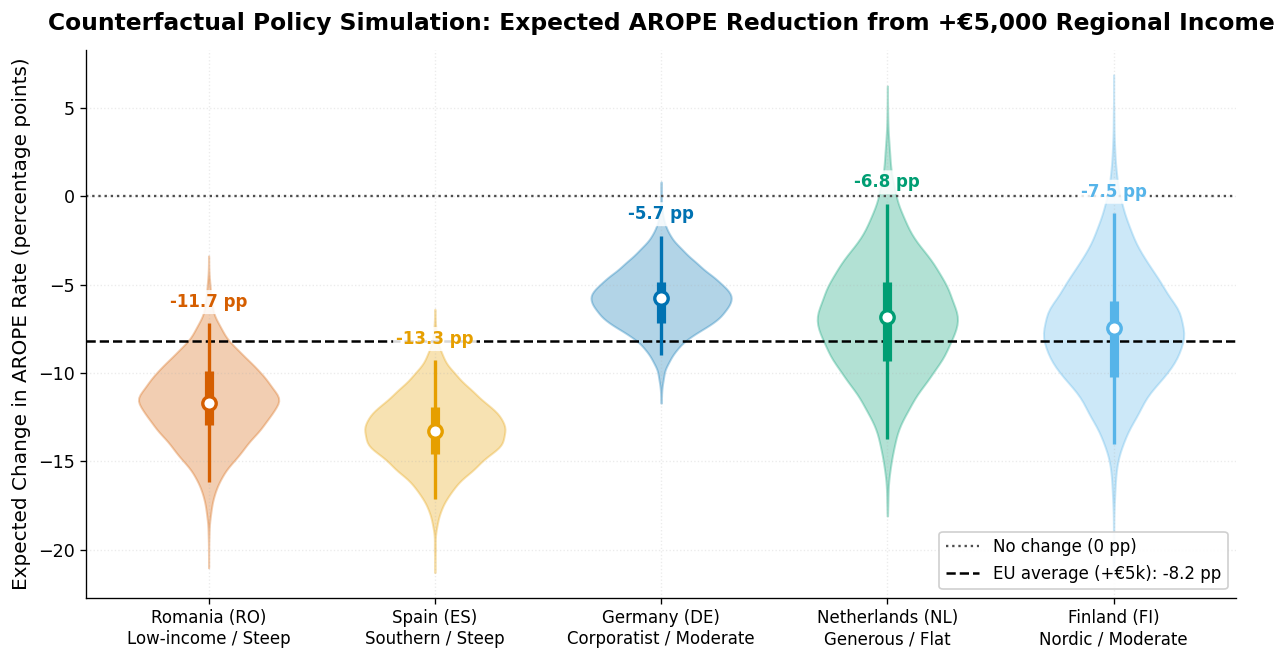

In [22]:
# Figure 12: Counterfactual Posterior Predictive Simulation (+€5,000 Disposable Income)
cf_countries = ["RO", "ES", "DE", "NL", "FI"]
cf_labels = {
    "RO": "Romania (RO)\nLow-income / Steep",
    "ES": "Spain (ES)\nSouthern / Steep",
    "DE": "Germany (DE)\nCorporatist / Moderate",
    "NL": "Netherlands (NL)\nGenerous / Flat",
    "FI": "Finland (FI)\nNordic / Moderate",
}

delta_inc_eur = 5000.0
cf_rows = []
cf_draws_dict = {}

for c in cf_countries:
    c_i = c_levels.index(c)
    # Expected AROPE change (pp) for +€5,000 disposable income, propagating full parameter uncertainty
    delta_pp_draws = total_slopes_pp[:, c_i] * (delta_inc_eur / 1000.0)
    cf_draws_dict[c] = delta_pp_draws
    h95_lo, h95_hi = az.hdi(delta_pp_draws, hdi_prob=0.95)
    h50_lo, h50_hi = az.hdi(delta_pp_draws, hdi_prob=0.50)
    cf_rows.append({
        "Country": c,
        "n_j": int(country_counts[c]),
        "Mean ΔAROPE (pp)": round(float(delta_pp_draws.mean()), 1),
        "SD (pp)": round(float(delta_pp_draws.std()), 1),
        "95% HDI (pp)": f"[{h95_lo:.1f}, {h95_hi:.1f}]",
        "P(Δ < -5 pp)": round(float(np.mean(delta_pp_draws < -5.0)), 2),
    })

cf_table = pd.DataFrame(cf_rows).set_index("Country")
print("=== Counterfactual Expected AROPE Change for +€5,000 Regional Disposable Income ===")
display(cf_table)

fig, ax = plt.subplots(figsize=(10.5, 5.6))
x_pos = np.arange(len(cf_countries))
cf_colors = [PALETTE["vermilion"], PALETTE["orange"], PALETTE["blue"], PALETTE["bluish_green"], PALETTE["sky_blue"]]

# Violin + 50%/95% HDI overlay
parts = ax.violinplot(
    [cf_draws_dict[c] for c in cf_countries],
    positions=x_pos,
    widths=0.62,
    showmeans=False,
    showmedians=False,
    showextrema=False,
)
for body, col in zip(parts["bodies"], cf_colors):
    body.set_facecolor(col)
    body.set_alpha(0.30)
    body.set_edgecolor(col)
    body.set_linewidth(1.2)

for idx, (c, col) in enumerate(zip(cf_countries, cf_colors)):
    d = cf_draws_dict[c]
    h95_lo, h95_hi = az.hdi(d, hdi_prob=0.95)
    h50_lo, h50_hi = az.hdi(d, hdi_prob=0.50)
    ax.vlines(idx, h95_lo, h95_hi, color=col, lw=2.0, zorder=3)
    ax.vlines(idx, h50_lo, h50_hi, color=col, lw=5.5, zorder=4)
    ax.scatter(idx, d.mean(), color="white", edgecolor=col, s=65, lw=2.0, zorder=5)
    ax.text(
        idx, h95_hi + 0.7, f"{d.mean():.1f} pp", ha="center", va="bottom",
        fontsize=10, fontweight="bold", color=col,
        bbox=dict(boxstyle="round,pad=0.18", facecolor="white", edgecolor="none", alpha=0.85),
    )

ax.axhline(0.0, color=PALETTE["slate"], ls=":", lw=1.4, label="No change (0 pp)")
ax.axhline(eu_mean_pp * 5.0, color="black", ls="--", lw=1.5, label=f"EU average (+€5k): {eu_mean_pp * 5.0:.1f} pp")
ax.set_xticks(x_pos)
ax.set_xticklabels([cf_labels[c] for c in cf_countries], fontsize=10)
ax.set_ylabel("Expected Change in AROPE Rate (percentage points)")
ax.set_title(
    "Counterfactual Policy Simulation: Expected AROPE Reduction from +€5,000 Regional Income",
    pad=12,
)
ax.legend(loc="lower right", frameon=True, framealpha=0.92)
plt.tight_layout()
save_fig(fig, "12_counterfactual_scenarios.png")
plt.show()

## Section 9: Summary, Limitations & AI Usage Note

### Key Findings Linked to the Research Question
1. **Substantial Cross-Country Heterogeneity (Simpson's Paradox Resolved):** Ignoring national boundaries (Model 1) severely attenuates the estimated income–poverty relationship ($r = -0.38$ pooled vs. $r = -0.70$ within-country) and fails to capture national baseline poverty levels. Allowing country-specific intercepts and income slopes (Model 2) yields an overwhelming out-of-sample predictive improvement ($\Delta\text{ELPD}_{\text{LOO}} > 100$, $> 8\,\text{SE}$) and cuts regional prediction RMSE nearly in half while raising Bayesian $R^2$ dramatically.
2. **National Welfare Regimes Shape Income Sensitivity:** While higher regional disposable income is strongly protective on average across Europe, the magnitude of protection varies widely across member states—from steep income gradients in countries like Romania and Spain to much flatter gradients in generous redistributive welfare regimes such as the Netherlands.
3. **Robustness & Diagnostics:** All primary and sensitivity chains achieved clean NUTS convergence ($\hat{R} \le 1.01$, Bulk/Tail ESS $> 400$, 0 divergences, E-BFMI $> 0.70$). Posterior predictive checks confirm strong marginal calibration, capture of the extreme upper tail (`FRY3` = 49.2%), and 100% coverage of observed country means. A conditional Student-$t$ check confirms near-Gaussian residuals ($\nu \approx 27$) and shows that the few Pareto $\hat{k} > 0.7$ observations arise from structural single- and two-region country leverage ($n_j \in \{1, 2\}$) rather than heavy-tailed likelihood misspecification.

### Modeling Limitations & Future Extensions
- **Cross-sectional 2022 design:** Associations reflect 2022 regional snapshots rather than causal income interventions; unobserved regional confounders (e.g., labor market composition, housing costs) are not isolated.
- **Ecological fallacy:** NUTS-2 aggregates mask within-region household inequality and urban–suburban pockets of deprivation.
- **Relative national poverty thresholds:** The at-risk-of-poverty component of AROPE is defined relative to 60% of *national* median equivalized income, which mechanically contributes to cross-country baseline and slope differences.
- **Future extensions:** (i) Incorporating correlated varying intercepts and slopes via an explicit PyMC LKJ Cholesky prior, (ii) spatial conditional autoregressive (CAR/BYM2) random effects for cross-border NUTS-2 adjacency, and (iii) multi-year longitudinal Eurostat panels to separate structural welfare regimes from macroeconomic shocks.

### AI Usage Disclosure (Aalto University Course Policy)
- *[Placeholder for final report submission: Document any AI coding/editorial assistance used during notebook auditing, plotting refinement, and text editing in accordance with CS-E5710 guidelines, noting that all statistical modeling decisions, diagnostic checks, and interpretations were verified by the authors.]*